# CS6140 Machine Learning — Fall 2026
# HW5 Starter — Neural Networks: Backprop, Training, VAE, GAN

This notebook implements `HW5_26F.html`. Read the HTML for the full problem statements; the markdown
cells here repeat the key instructions next to the code.

| Problem | Topic | Points |
|---|---|---|
| 1 | Backpropagation from scratch: the 8-3-8 autoencoder | 50 |
| 2 | A classifier network: build it (numpy, then PyTorch/d2l), then train it well | 100 |
| 3 | Variational autoencoder (VAE) on MNIST | 50 |
| 4 | Generative adversarial network (GAN): run it and explain it (code given) | 10 |
| 5, 6 | THEORY: dropout; diagnosing the learning rate | 25 + 25 |
| 8 | optional: backprop in matrix form (7, DCGAN, is HTML-only) | no credit |

**How to work through this notebook.** Everything runs as given except the lines marked
`### TODO_STUDENT ###`: their code has been replaced by `...` plus a one-line description of what
goes there. Replace each `...` with real code. Until you do, the cell (or a later cell that uses it)
will fail or print nonsense. That's expected, not a bug. Written answers go in the markdown cells
that say *Your answer here*.

**Checkpoint cells** follow each piece you implement. They test your code against a numerical
check or the matching PyTorch function, and fail with a message if something is off. Don't move
on until the checkpoint above you passes: a network trained on a wrong gradient can still *look*
like it's learning.

**Work top to bottom.** Problem 2 reuses Problem 1's layer classes; Problem 3's plain autoencoder
reuses your VAE; Problem 4's GAN is complete code to run and explain. The whole notebook, once filled in,
runs in about 3–5 minutes on a laptop CPU.

**Setup.** If the first cell fails, see the course's *NN setup page*. The data goes into the shared
`data/` folder next to your HW folders and is downloaded on first run (Fashion-MNIST and MNIST, about
150 MB; the Wine files); nothing to do by hand.

**Requirements.**
1. Fill in every `TODO_STUDENT` blank in the required problems according to the algorithm steps
   covered in lecture and the linked materials, and make sure the notebook runs top to bottom
   without errors. (Blanks in the optional problems are not required.)
2. Understand the *whole* notebook — including the provided/given code, not just the blanks you
   filled in — well enough to explain any part of it during office hours.


In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torchvision
from d2l import torch as d2l
from tqdm import tqdm
from IPython.display import display


def get_device():
    if torch.cuda.is_available():            # NVIDIA GPU
        return torch.device('cuda')
    if torch.backends.mps.is_available():    # Apple Silicon GPU
        return torch.device('mps')
    return torch.device('cpu')


DEVICE = get_device()
if DEVICE.type == 'mps':   # d2l only knows CUDA: point its GPU helpers at Apple's GPU
    d2l.num_gpus = lambda: 1
    d2l.gpu = lambda i=0: DEVICE
    d2l.try_gpu = lambda i=0: DEVICE
print('Best available device:', DEVICE)

# HW5's networks are small. On the machines we tested, the CPU trains them as fast as, or faster
# than, a GPU (moving tiny batches to the GPU costs more than the math), so HW5 trains everything on
# the CPU. HW6-HW7's bigger models will use DEVICE.
TRAIN_DEVICE = torch.device('cpu')

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

import os
import urllib.request

# The shared data folder: cs6140/data, next to your HW folders (NN setup page, section 3).
DATA = next((d for d in ["../data", "../../data", "../../../data"] if os.path.isdir(d)), "../data")
COURSE_DATA_URL = "https://www.khoury.northeastern.edu/home/vip/teach/MLcourse/data"


def course_file(name, fallback_url=None):
    """DATA/name. Downloaded the first time from the course website (or from fallback_url)."""
    path = os.path.join(DATA, name)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        for url in [f"{COURSE_DATA_URL}/{name}"] + ([fallback_url] if fallback_url else []):
            try:
                print(f"downloading {name} from {url} ...")
                urllib.request.urlretrieve(url, path + ".part")
                os.replace(path + ".part", path)
                break
            except OSError as err:
                print(f"  failed: {err}")
        else:
            raise FileNotFoundError(f"could not download {name}: put it into {os.path.abspath(DATA)}")
    return path
TORCH_DATA = f"{DATA}/torchvision"           # Fashion-MNIST + MNIST download here (~150 MB)


# --- Progress bars (nothing to do here) ---
class _BarOutput:
    """Where tqdm writes its bar: ONE notebook output, updated in place (not a new line per redraw).
    Inside a d2l live plot, the bar becomes the plot's title instead, because d2l clears the cell's
    output on every redraw and would erase a separate bar."""

    def __init__(self, board=None):
        self.board, self.handle = board, None

    def write(self, text):
        text = text.strip("\r\n")
        if not text:
            return
        if self.board is not None:
            if self.board.fig is not None:
                self.board.fig.suptitle(text, fontsize=8, family="monospace")
        elif self.handle is None:
            self.handle = display({"text/plain": text}, raw=True, display_id=True)
        else:
            self.handle.update({"text/plain": text}, raw=True)

    def flush(self):
        pass


def progress(total, desc, unit="batch", board=None):
    """A progress bar for a training loop: call .update(1) per step, .close() at the end."""
    width = 25 if board is None else 12
    fmt = "{desc}: {percentage:3.0f}%|{bar:" + str(width) + "}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}{postfix}]"
    return tqdm(total=total, desc=desc, unit=unit, file=_BarOutput(board), mininterval=0.5, ascii=False,
                bar_format=fmt)


def _fit_with_progress(self, model, data):
    """d2l.Trainer.fit, plus a progress bar over all training batches (shown as the live plot's title)."""
    self.prepare_data(data)
    self.prepare_model(model)
    self.optim = model.configure_optimizers()
    self.epoch = self.train_batch_idx = self.val_batch_idx = 0
    board = model.board if model.board.display else None
    if board is not None:
        board.figsize = (5.5, 3.2)                  # room for the bar in the title
    bar = progress(self.max_epochs * self.num_train_batches, type(model).__name__, board=board)
    loader = self.train_dataloader
    self.train_dataloader = _TickingLoader(loader, bar)
    try:
        for self.epoch in range(self.max_epochs):
            self.fit_epoch()
            bar.set_postfix(epoch=self.epoch + 1)
    finally:
        self.train_dataloader = loader
        bar.close()


class _TickingLoader:
    """Wraps a DataLoader so that every batch it hands out advances the progress bar."""
    def __init__(self, loader, bar):
        self.loader, self.bar = loader, bar
    def __iter__(self):
        for batch in self.loader:
            yield batch
            self.bar.update(1)
    def __len__(self):
        return len(self.loader)


d2l.Trainer.fit = _fit_with_progress


Best available device: mps


## Data

* **Wine** (Problem 2, for debugging): 3 classes, 13 features. Column 0 of the CSV is the class label
  (1, 2, 3), which we shift to 0, 1, 2. Features are standardized with *training* statistics.
* **Fashion-MNIST** (Problem 2): 28×28 grayscale clothing images, 10 classes. It's the same data
  `d2l.FashionMNIST` wraps; we load it through `torchvision` so that numpy (Part I) and PyTorch
  (Parts I–II) see exactly the same arrays. Each image is flattened to a vector of 784 pixel values
  in [0, 1].
* **MNIST** (Problem 3): handwritten digits, same format.
* **2gaussian.txt / 3gaussian.txt** (Problems 4, 7): HW4's 2-D Gaussian-mixture data.


Wine: (151, 13) (28, 13) class counts (train): [50 58 43]
Fashion-MNIST: (60000, 784) (10000, 784)
MNIST: (60000, 784) (10000, 784)
2gaussian: (6000, 2)  3gaussian: (10000, 2)


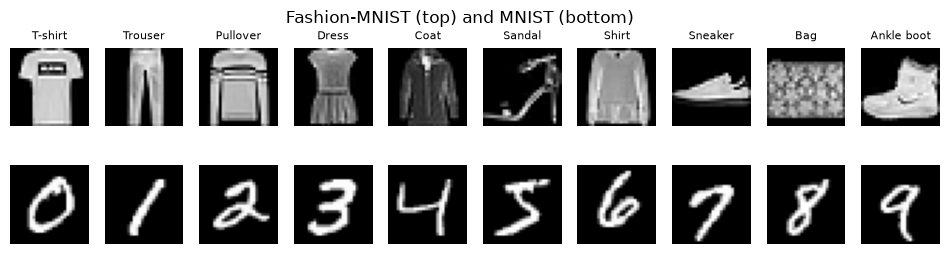

In [2]:
def load_wine(path):
    a = np.loadtxt(path, delimiter=",")
    return a[:, 1:], a[:, 0].astype(int) - 1     # column 0 = class label 1..3  ->  0..2


X_wine_tr, y_wine_tr = load_wine(course_file("train_wine.csv"))
X_wine_te, y_wine_te = load_wine(course_file("test_wine.csv"))
wine_mean, wine_std = X_wine_tr.mean(axis=0), X_wine_tr.std(axis=0)
X_wine_tr = (X_wine_tr - wine_mean) / wine_std
X_wine_te = (X_wine_te - wine_mean) / wine_std
print("Wine:", X_wine_tr.shape, X_wine_te.shape, "class counts (train):", np.bincount(y_wine_tr))


def load_images(dataset_class, train):
    """Flattened images as float64 numpy (pixels in [0,1]) and integer labels."""
    ds = dataset_class(root=TORCH_DATA, train=train, download=True)
    X = ds.data.reshape(len(ds), -1).numpy().astype(np.float64) / 255.0
    return X, ds.targets.numpy()


X_fm_tr, y_fm_tr = load_images(torchvision.datasets.FashionMNIST, train=True)
X_fm_te, y_fm_te = load_images(torchvision.datasets.FashionMNIST, train=False)
FM_CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
              "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("Fashion-MNIST:", X_fm_tr.shape, X_fm_te.shape)

# float32 torch copies of the same arrays, for the PyTorch parts
Xt_fm_tr, yt_fm_tr = torch.tensor(X_fm_tr, dtype=torch.float32), torch.tensor(y_fm_tr)
Xt_fm_te, yt_fm_te = torch.tensor(X_fm_te, dtype=torch.float32), torch.tensor(y_fm_te)

X_mn_tr, y_mn_tr = load_images(torchvision.datasets.MNIST, train=True)
X_mn_te, y_mn_te = load_images(torchvision.datasets.MNIST, train=False)
Xt_mn_tr, yt_mn_tr = torch.tensor(X_mn_tr, dtype=torch.float32), torch.tensor(y_mn_tr)
Xt_mn_te, yt_mn_te = torch.tensor(X_mn_te, dtype=torch.float32), torch.tensor(y_mn_te)
print("MNIST:", X_mn_tr.shape, X_mn_te.shape)

gauss2 = np.loadtxt(course_file("2gaussian.txt", "https://www.khoury.northeastern.edu/home/vip/teach/MLcourse/3_generative_models/HW3/2gaussian.txt"))
gauss3 = np.loadtxt(course_file("3gaussian.txt", "https://www.khoury.northeastern.edu/home/vip/teach/MLcourse/3_generative_models/HW3/3gaussian.txt"))
print("2gaussian:", gauss2.shape, " 3gaussian:", gauss3.shape)

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for i in range(10):
    axes[0, i].imshow(X_fm_tr[np.where(y_fm_tr == i)[0][0]].reshape(28, 28), cmap="gray")
    axes[0, i].set_title(FM_CLASSES[i], fontsize=8)
    axes[1, i].imshow(X_mn_tr[np.where(y_mn_tr == i)[0][0]].reshape(28, 28), cmap="gray")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Fashion-MNIST (top) and MNIST (bottom)")
plt.show()


---
## Problem 1 — Backpropagation from Scratch: the 8-3-8 Autoencoder  [50 points]

A network with 8 inputs, 3 hidden units, 8 outputs, all sigmoid, trained so that each of the 8
one-hot inputs is reproduced at the output (see the table in the HTML). The point is *how* you build
it: as a chain of layers, each knowing its own forward and backward pass — the same design PyTorch
uses (d2l 5.3).

**Conventions** (row-vector convention, as in the Regression notes). A batch `x` has shape
(n, n_in). A `Linear` layer computes `x @ W + b` with `W` of shape (n_in, n_out). `backward(grad_out)`
receives dL/d(output) of shape (n, n_out) and returns dL/d(input) of shape (n, n_in). The square
loss is averaged over the batch: L = (1/2n) Σᵢ ‖ŷᵢ − yᵢ‖².

### (A) Layers with forward and backward  [15 points]


In [3]:
class Linear:
    """Fully-connected layer: out = x @ W + b, with x of shape (n, n_in)."""

    def __init__(self, n_in, n_out, rng, scale=None):
        # default init = PyTorch's nn.Linear default: uniform in +-1/sqrt(n_in)
        bound = 1.0 / np.sqrt(n_in) if scale is None else scale
        self.W = rng.uniform(-bound, bound, size=(n_in, n_out))
        self.b = rng.uniform(-bound, bound, size=n_out)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, x):
        self.x = x                       # cache the input: backward needs it for dL/dW
        return x @ self.W + self.b  ### TODO_STUDENT ### the affine map  x W + b

    def backward(self, grad_out):
        self.dW = self.x.T @ grad_out  ### TODO_STUDENT ### dL/dW = x^T (dL/dout)  (sums over the batch)
        self.db = grad_out.sum(axis=0)  ### TODO_STUDENT ### dL/db = dL/dout summed over the batch
        return grad_out @ self.W.T  ### TODO_STUDENT ### dL/dx = (dL/dout) W^T, handed to the previous layer


class Sigmoid:
    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))  ### TODO_STUDENT ### sigma(x); cache it, backward needs it
        return self.out

    def backward(self, grad_out):
        return grad_out * self.out * (1 - self.out)  ### TODO_STUDENT ### chain rule with sigma'(x) = sigma(x) (1 - sigma(x))


class SquareLoss:
    """L = (1/2n) sum_i ||y_hat_i - y_i||^2."""

    def forward(self, y_hat, y):
        self.diff = y_hat - y
        return 0.5 * np.sum(self.diff ** 2) / len(self.diff)  ### TODO_STUDENT ### the loss value

    def backward(self):
        return self.diff / len(self.diff)  ### TODO_STUDENT ### dL/dy_hat


class Network:
    """A list of layers plus a loss layer. forward runs the layers in order; backward runs them
    in reverse, each layer handing its input-gradient to the layer before it."""

    def __init__(self, layers, loss):
        self.layers, self.loss = layers, loss

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)  ### TODO_STUDENT ### run each layer in order
        return x

    def backward(self):
        grad = self.loss.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)  ### TODO_STUDENT ### pass the gradient back through each layer, last to first

    def linear_layers(self):
        return [layer for layer in self.layers if isinstance(layer, Linear)]

    def sgd_step(self, lr):
        for layer in self.linear_layers():
            layer.W -= lr * layer.dW  ### TODO_STUDENT ### gradient descent update of W
            layer.b -= lr * layer.db  ### TODO_STUDENT ### gradient descent update of b


### (B) Check the gradients, two ways  [15 points]

Both checkers are given. Your job is to make them pass.

1. **Numerically:** every weight's backprop gradient vs. the centered finite difference
   (L(w+ε) − L(w−ε)) / 2ε, with ε = 10⁻⁵, in float64. The maximum relative error should be below 10⁻⁶.
2. **Against PyTorch autograd:** the same network built from `nn.Linear` + `nn.Sigmoid`, with *your*
   weights copied in; PyTorch's gradients must equal yours.


In [4]:
def numerical_gradient_check(net, X, Y, eps=1e-5):
    """Max relative error between backprop and centered finite differences, over ALL weights and biases."""
    net.loss.forward(net.forward(X), Y)
    net.backward()
    worst = 0.0
    for li, layer in enumerate(net.linear_layers()):
        for name, P, dP in [("W", layer.W, layer.dW.copy()), ("b", layer.b, layer.db.copy())]:
            num = np.zeros_like(P)
            for idx in np.ndindex(P.shape):
                old = P[idx]
                P[idx] = old + eps
                L_plus = net.loss.forward(net.forward(X), Y)
                P[idx] = old - eps
                L_minus = net.loss.forward(net.forward(X), Y)
                P[idx] = old
                num[idx] = (L_plus - L_minus) / (2 * eps)
            rel = np.abs(num - dP) / np.maximum(np.abs(num) + np.abs(dP), 1e-8)
            print(f"  Linear layer {li}, {name}: max relative error {rel.max():.2e}")
            worst = max(worst, rel.max())
    return worst


def autograd_check(net, X, Y):
    """Rebuild `net` from nn layers with the SAME weights and compare PyTorch's gradients to yours."""
    torch_layers = []
    for layer in net.layers:
        if isinstance(layer, Linear):
            lin = nn.Linear(*layer.W.shape).double()
            with torch.no_grad():
                lin.weight.copy_(torch.tensor(layer.W.T))   # nn.Linear stores W transposed: (n_out, n_in)
                lin.bias.copy_(torch.tensor(layer.b))
            torch_layers.append(lin)
        elif type(layer).__name__ == "Sigmoid":
            torch_layers.append(nn.Sigmoid())
        elif type(layer).__name__ == "ReLU":
            torch_layers.append(nn.ReLU())
    tnet = nn.Sequential(*torch_layers)
    Xt, Yt = torch.tensor(X), torch.tensor(Y)
    loss = 0.5 * nn.MSELoss(reduction="sum")(tnet(Xt), Yt) / len(X)   # the same loss as SquareLoss
    loss.backward()
    net.loss.forward(net.forward(X), Y)
    net.backward()
    torch_linears = [m for m in tnet if isinstance(m, nn.Linear)]
    for lin, layer in zip(torch_linears, net.linear_layers()):
        torch.testing.assert_close(lin.weight.grad.T, torch.tensor(layer.dW))
        torch.testing.assert_close(lin.bias.grad, torch.tensor(layer.db))
    print("  PyTorch autograd agrees with your backprop on every weight and bias.")


# CHECKPOINT: a fresh 8-3-8 network, before any training
X_ae = np.eye(8)                       # the 8 one-hot inputs; the targets are the same 8 vectors
rng = np.random.default_rng(SEED)
check_net = Network([Linear(8, 3, rng, scale=0.5), Sigmoid(), Linear(3, 8, rng, scale=0.5), Sigmoid()], SquareLoss())
print("(i) numerical gradient check:")
worst = numerical_gradient_check(check_net, X_ae, X_ae)
assert worst < 1e-6, f"max relative error {worst:.1e} >= 1e-6: some backward() is wrong (see the per-layer lines above)"
print("(ii) autograd check:")
autograd_check(check_net, X_ae, X_ae)
print("CHECKPOINT PASSED")


(i) numerical gradient check:
  Linear layer 0, W: max relative error 1.00e-08
  Linear layer 0, b: max relative error 7.99e-10
  Linear layer 1, W: max relative error 1.08e-10
  Linear layer 1, b: max relative error 6.30e-11
(ii) autograd check:
  PyTorch autograd agrees with your backprop on every weight and bias.
CHECKPOINT PASSED


### (C) Train it, and read what it learned  [20 points]

Full-batch gradient descent on all 8 examples, from random initial weights (uniform in ±0.5, so the
network doesn't start at a solution). The learning rate is large (5.0) because the loss is averaged
over only 8 examples and the sigmoid's slope is at most 1/4; 5,000 iterations take well under a second.


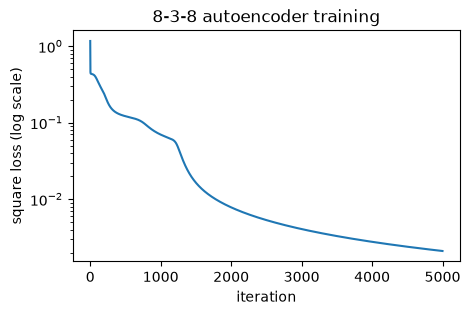

input   hidden values        rounded   reconstructed as
  0     [0.33 0.99 0.01]   010       0
  1     [0.98 0.01 0.89]   101       1
  2     [1.00 0.66 0.02]   110       2
  3     [0.01 0.99 0.93]   011       3
  4     [0.00 0.28 0.10]   000       4
  5     [0.57 0.01 0.01]   100       5
  6     [0.99 0.99 0.99]   111       6
  7     [0.11 0.03 0.98]   001       7
final loss 0.0021;  distinct 3-bit codes: 8 of 8;  all 8 reconstructed: True


In [5]:
rng = np.random.default_rng(1)
ae = Network([Linear(8, 3, rng, scale=0.5), Sigmoid(), Linear(3, 8, rng, scale=0.5), Sigmoid()], SquareLoss())
lr, n_iters = 5.0, 5000
losses = []
for it in range(n_iters):
    loss = ae.loss.forward(ae.forward(X_ae), X_ae)  ### TODO_STUDENT ### forward pass and loss on all 8 examples
    ae.backward()  ### TODO_STUDENT ### backpropagate
    ae.sgd_step(lr)  ### TODO_STUDENT ### one gradient descent step
    losses.append(loss)

plt.figure(figsize=(5, 3))
plt.semilogy(losses)
plt.xlabel("iteration"); plt.ylabel("square loss (log scale)"); plt.title("8-3-8 autoencoder training")
plt.show()

ae.forward(X_ae)
H = ae.layers[1].out            # the hidden (Sigmoid) layer's output for the 8 inputs
recon = ae.forward(X_ae).argmax(axis=1)
print("input   hidden values        rounded   reconstructed as")
for i in range(8):
    print(f"  {i}     {np.array2string(H[i], precision=2, floatmode='fixed')}   {''.join(str(int(v > 0.5)) for v in H[i])}       {recon[i]}")
codes = {tuple((H[i] > 0.5).astype(int)) for i in range(8)}
print(f"final loss {losses[-1]:.4f};  distinct 3-bit codes: {len(codes)} of 8;  all 8 reconstructed: {np.all(recon == np.arange(8))}")


**Written answer (C).** Since the outputs equal the inputs, this network is an encoder-decoder. What does training achieve in this context, and why is the 3-unit hidden layer (rather than, say, 8 units) essential to that?

*How to think about it.* Round each hidden value in your table to 0 or 1. How many different patterns can 3 binary units show, and how many inputs must be told apart? Then imagine the same network with 8 hidden units: what is the laziest way it could reproduce its input, and would its hidden layer then tell you anything about the data? Think of the hidden layer as the only "message" the encoder may send to the decoder.

*Your answer here.*

The encoder takes the 8 numbers of each input and squeezes them into 3 numbers (the encoding in the hidden layer). The decoder uses only those 3 numbers to rebuild the original 8 numbers from the input. So training the network means learning 2 things: encoding and decoding. Essentially doing feature reduction. 
Rounding the values from the hidden layer to 0 or 1, it produces 3-bit codes, and all 8 are distinct, so every input is re-constructed. 3 bits can show only 8 patterns, which matches the number of inputs, so the network is forced to learn an encoding that fits these 3 bits. 
Same network with 8 hidden units would not have to encode or decode since there is no feature reduction, the eight units can represent the input as it is, so nothing new is learned from the input. The hidden layer would just be a copy of the input. Hence the encoder and decoder will do no work in this case and the error would be close to zero.


---
## Problem 2 — A Classifier Network: Build It, Then Train It Well (Fashion-MNIST)  [100 points]

**Part I** builds a multiclass network three ways: from scratch, with the wrong loss, and in
PyTorch. **Part II** takes the PyTorch version and studies the training choices that decide whether
a network learns well, badly, or not at all.

### Part I — Build it

### (A) From scratch: ReLU, softmax + cross-entropy, minibatch SGD  [25 points]

The output layer is a **softmax**, pᵢₖ = exp(oᵢₖ) / Σⱼ exp(oᵢⱼ), trained with **cross-entropy**
L = −(1/n) Σᵢ log pᵢ,yᵢ — maximum likelihood, the same objective as HW2's logistic regression, now
with a hidden layer in front. Written as one combined layer, its backward pass is just
(softmax(o) − onehot(y)) / n: see Equation 4 of the NN_BASICS note (§5.2); the derivation is in
§2 of the NN_ADVANCED note.


In [6]:
class ReLU:
    def forward(self, x):
        self.mask = x > 0  ### TODO_STUDENT ### remember where the input was positive
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask  ### TODO_STUDENT ### ReLU'(x) = 1 where x > 0, else 0


class SoftmaxCrossEntropy:
    """Softmax output + cross-entropy loss as ONE layer. y holds integer labels 0..K-1."""

    def forward(self, o, y):
        o = o - o.max(axis=1, keepdims=True)  ### TODO_STUDENT ### subtract each row's max (numerical stability; softmax is unchanged)
        e = np.exp(o)
        self.p = e / e.sum(axis=1, keepdims=True)  ### TODO_STUDENT ### softmax probabilities, one row per example
        self.y = y
        return -np.mean(np.log(self.p[np.arange(len(y)), y]))  ### TODO_STUDENT ### mean negative log-probability of the true class

    def backward(self):
        grad = self.p.copy()
        grad[np.arange(len(self.y)), self.y] -= 1  ### TODO_STUDENT ### softmax(o) - onehot(y)
        return grad / len(self.y)


# CHECKPOINT: gradient check of the new layers on a small Wine batch
rng = np.random.default_rng(SEED)
chk = Network([Linear(13, 5, rng), ReLU(), Linear(5, 3, rng)], SoftmaxCrossEntropy())
worst = numerical_gradient_check(chk, X_wine_tr[:20], y_wine_tr[:20])
assert worst < 1e-6, f"max relative error {worst:.1e}: check ReLU / SoftmaxCrossEntropy backward"
print("CHECKPOINT PASSED")


  Linear layer 0, W: max relative error 1.10e-08
  Linear layer 0, b: max relative error 7.44e-10
  Linear layer 1, W: max relative error 4.11e-10
  Linear layer 1, b: max relative error 2.00e-10
CHECKPOINT PASSED


Wine, from scratch (lr=0.1, 100 epochs, batch 16):


Wine, k=4: 100%|█████████████████████████| 1000/1000 [00:00<00:00, 6111.28batch/s, epoch=100, train_acc=1.000]

  k=  4: train 1.000   test 1.000


Wine, k=16: 100%|█████████████████████████| 1000/1000 [00:00<00:00, 9943.61batch/s, epoch=100, train_acc=1.000]

  k= 16: train 1.000   test 1.000


Wine, k=64: 100%|█████████████████████████| 1000/1000 [00:00<00:00, 8672.10batch/s, epoch=100, train_acc=1.000]

  k= 64: train 1.000   test 1.000


Fashion-MNIST, cross-entropy: 100%|█████████████████████████| 2350/2350 [00:04<00:00, 490.28batch/s, epoch=10, train_acc=0.866]


Fashion-MNIST, from scratch (lr=0.1, 10 epochs, batch 256): train 0.866   test 0.851   (4.8 s)


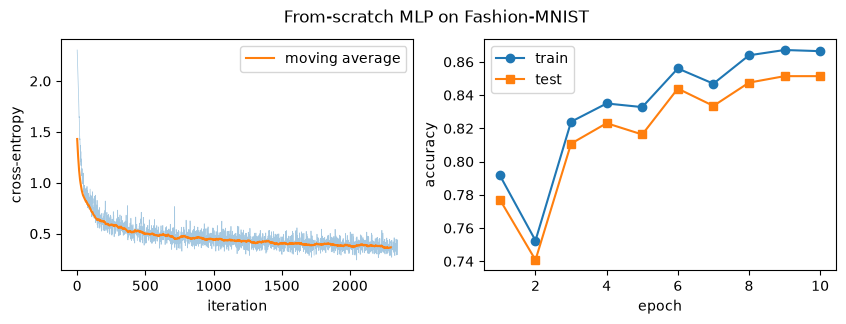

In [7]:
def accuracy_scratch(net, X, y):
    return np.mean(net.forward(X).argmax(axis=1) == y)


def train_scratch(net, X, y, lr, epochs, batch_size, rng, X_test=None, y_test=None, targets=None, desc="from scratch"):
    """Minibatch SGD. `targets` (optional) is what the loss compares against instead of y -- e.g.
    one-hot vectors for the square loss in (B). Accuracy is always measured against the labels y."""
    T = y if targets is None else targets
    hist = {"loss": [], "train_acc": [], "test_acc": []}
    bar = progress(epochs * -(-len(X) // batch_size), desc)
    for epoch in range(epochs):
        perm = rng.permutation(len(X))                  # a fresh random order every epoch
        for start in range(0, len(X), batch_size):
            idx = perm[start:start + batch_size]
            loss = net.loss.forward(net.forward(X[idx]), T[idx])  ### TODO_STUDENT ### forward pass + loss on this minibatch
            net.backward()  ### TODO_STUDENT ### backpropagate
            net.sgd_step(lr)  ### TODO_STUDENT ### SGD update
            hist["loss"].append(loss)
            bar.update(1)
        hist["train_acc"].append(accuracy_scratch(net, X, y))
        bar.set_postfix(epoch=epoch + 1, train_acc=f"{hist['train_acc'][-1]:.3f}")
        if X_test is not None:
            hist["test_acc"].append(accuracy_scratch(net, X_test, y_test))
    bar.close()
    return hist


# --- Wine: 13-k-3, trains in well under a second ---
print("Wine, from scratch (lr=0.1, 100 epochs, batch 16):")
wine_scratch = {}
for k in [4, 16, 64]:
    rng = np.random.default_rng(SEED)
    net = Network([Linear(13, k, rng), ReLU(), Linear(k, 3, rng)], SoftmaxCrossEntropy())
    train_scratch(net, X_wine_tr, y_wine_tr, lr=0.1, epochs=100, batch_size=16, rng=rng, desc=f"Wine, k={k}")
    wine_scratch[k] = (accuracy_scratch(net, X_wine_tr, y_wine_tr), accuracy_scratch(net, X_wine_te, y_wine_te))
    print(f"  k={k:3d}: train {wine_scratch[k][0]:.3f}   test {wine_scratch[k][1]:.3f}")

# --- Fashion-MNIST: 784-256-10, the same code ---
rng = np.random.default_rng(SEED)
fm_scratch = Network([Linear(784, 256, rng), ReLU(), Linear(256, 10, rng)], SoftmaxCrossEntropy())
t0 = time.time()
hist_fm_ce = train_scratch(fm_scratch, X_fm_tr, y_fm_tr, lr=0.1, epochs=10, batch_size=256, rng=rng,
                           X_test=X_fm_te, y_test=y_fm_te, desc="Fashion-MNIST, cross-entropy")
print(f"\nFashion-MNIST, from scratch (lr=0.1, 10 epochs, batch 256): "
      f"train {hist_fm_ce['train_acc'][-1]:.3f}   test {hist_fm_ce['test_acc'][-1]:.3f}   ({time.time() - t0:.1f} s)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(hist_fm_ce["loss"], alpha=0.4, lw=0.5)
axes[0].plot(np.convolve(hist_fm_ce["loss"], np.ones(50) / 50, mode="valid"), lw=1.5, label="moving average")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("cross-entropy"); axes[0].legend()
axes[1].plot(range(1, 11), hist_fm_ce["train_acc"], "o-", label="train")
axes[1].plot(range(1, 11), hist_fm_ce["test_acc"], "s-", label="test")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
plt.suptitle("From-scratch MLP on Fashion-MNIST"); plt.show()


### (B) Why cross-entropy?  [10 points]

The same network and budget (10 epochs, **same learning rate 0.1**), but with Problem 1's recipe:
sigmoid outputs and square loss against one-hot targets. The two losses aren't on the same scale, so
we compare test accuracy per epoch, and plot each loss on its own axis.


Fashion-MNIST, square loss: 100%|█████████████████████████| 2350/2350 [00:03<00:00, 641.92batch/s, epoch=10, train_acc=0.830]

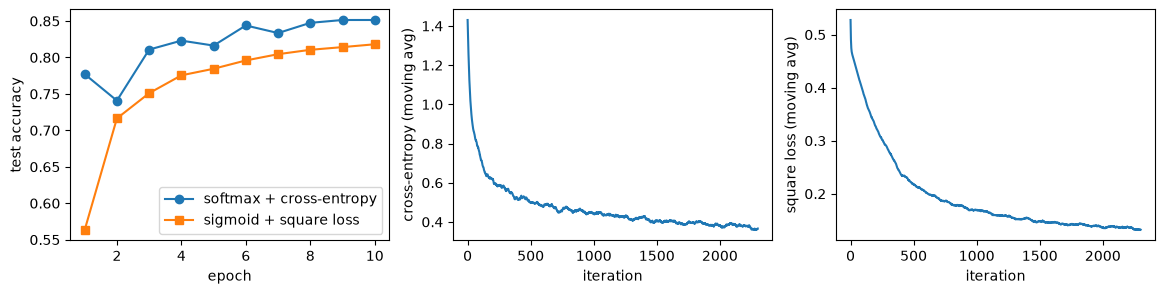

test accuracy per epoch
  cross-entropy: [0.777 0.741 0.811 0.823 0.816 0.844 0.834 0.848 0.851 0.851]
  square loss:   [0.563 0.716 0.751 0.776 0.784 0.796 0.804 0.81  0.814 0.818]

confidently wrong output (o = -5.0):
  cross-entropy gradient  p - 1                = -0.9933
  square-loss gradient    (s - 1) * s * (1 - s) = -0.0066


In [8]:
Y_fm_onehot = np.eye(10)[y_fm_tr]
rng = np.random.default_rng(SEED)
fm_square = Network([Linear(784, 256, rng), ReLU(), Linear(256, 10, rng), Sigmoid()], SquareLoss())  ### TODO_STUDENT ### the same 784-256-10 net, but with sigmoid outputs and the square loss
hist_fm_sq = train_scratch(fm_square, X_fm_tr, y_fm_tr, lr=0.1, epochs=10, batch_size=256, rng=rng, desc="Fashion-MNIST, square loss",
                           X_test=X_fm_te, y_test=y_fm_te, targets=Y_fm_onehot)

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(range(1, 11), hist_fm_ce["test_acc"], "o-", label="softmax + cross-entropy")
axes[0].plot(range(1, 11), hist_fm_sq["test_acc"], "s-", label="sigmoid + square loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("test accuracy"); axes[0].legend()
for ax, h, name in [(axes[1], hist_fm_ce, "cross-entropy"), (axes[2], hist_fm_sq, "square loss")]:
    ax.plot(np.convolve(h["loss"], np.ones(50) / 50, mode="valid"))
    ax.set_xlabel("iteration"); ax.set_ylabel(name + " (moving avg)")
plt.show()
print("test accuracy per epoch")
print("  cross-entropy:", np.round(hist_fm_ce["test_acc"], 3))
print("  square loss:  ", np.round(hist_fm_sq["test_acc"], 3))

# The output-layer gradient for ONE confidently wrong output: true class, but score o = -5
o = -5.0
p_softmax_like = 1 / (1 + np.exp(-o))       # the probability the model gives the true class (~0.007)
print(f"\nconfidently wrong output (o = {o}):")
print(f"  cross-entropy gradient  p - 1                = {p_softmax_like - 1:+.4f}")
print(f"  square-loss gradient    (s - 1) * s * (1 - s) = {(p_softmax_like - 1) * p_softmax_like * (1 - p_softmax_like):+.4f}")


**Written answer (B).** In 2–3 sentences, explain the difference using the output-layer gradient: compare the softmax/cross-entropy gradient from (A) with what the sigmoid's derivative does to the square-loss gradient when an output is confidently wrong.

*How to think about it.* Write the gradient that reaches one output unit's score in each case: (p − t) for softmax + cross-entropy, and (z − t)·z(1 − z) for sigmoid + square loss. Plug in a confidently wrong output, e.g. target t = 1 but output 0.01. How large is each gradient? Early in training many outputs are wrong: which loss gives those units a strong push? (The by-hand example in the NN_BASICS note, §7, shows the same effect with numbers.)

*Your answer here.*

With sigmoid + square loss, the error signal at an output is δ = (z − t)·f′(net), and for the sigmoid f′(net) = z(1 − z) (p.3). When an output is confidently wrong (true class, but z close to 0), z(1 − z) is close to 0 and shrinks the gradient almost to nothing: −0.0066 instead of −0.9933 for o = −5. Softmax + cross-entropy has no f′ factor (its gradient is just p − t), so the more wrong an output is, the harder it gets pushed to fix it, which is why it reaches 0.77 test accuracy after epoch 1 vs 0.56 for square loss at the same learning rate 0.1.

### (C) Using PyTorch / d2l  [15 points]

The same 784-256-10 architecture as a d2l `Classifier` (d2l supplies the cross-entropy loss, the
accuracy, and plain SGD with learning rate `lr`), trained by `d2l.Trainer` with the same settings as
(A). PyTorch's default `nn.Linear` initialization is uniform in ±1/√n_in, the same as our `Linear`, so
the two networks start from statistically identical weights (though not the same random draws).


MLPClassifier: 100%|█████████████████████████| 1000/1000 [00:00<00:00, 3584.39batch/s, epoch=100]

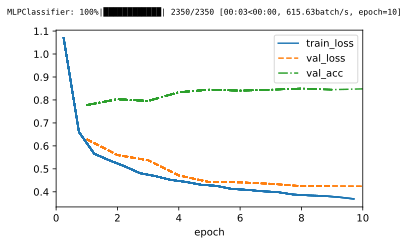

In [9]:
class ArrayData(d2l.DataModule):
    """In-memory tensors as a d2l DataModule: train = shuffled minibatches, val = the test set."""

    def __init__(self, X_train, y_train, X_val, y_val, batch_size):
        super().__init__()
        self.save_hyperparameters()

    def get_dataloader(self, train):
        tensors = (self.X_train, self.y_train) if train else (self.X_val, self.y_val)
        return self.get_tensorloader(tensors, train)


class MLPClassifier(d2l.Classifier):
    """Part I's network from nn layers: Flatten -> Linear -> ReLU -> Linear (softmax is inside the loss)."""

    def __init__(self, n_in, n_hidden, n_out, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_out))  ### TODO_STUDENT ### the same architecture as (A), from nn layers


def accuracy_torch(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(dim=1) == y).float().mean().item()


# --- Fashion-MNIST ---
torch.manual_seed(SEED)
fm_torch = MLPClassifier(784, 256, 10, lr=0.1)
fm_data = ArrayData(Xt_fm_tr, yt_fm_tr, Xt_fm_te, yt_fm_te, batch_size=256)
t0 = time.time()
d2l.Trainer(max_epochs=10, num_gpus=0).fit(fm_torch, fm_data)  ### TODO_STUDENT ### train for 10 epochs with d2l's Trainer (num_gpus=0: CPU)
fm_torch_time = time.time() - t0

# --- Wine (13-16-3; the progress plot is switched off for this tiny run) ---
torch.manual_seed(SEED)
wine_torch = MLPClassifier(13, 16, 3, lr=0.1)
wine_torch.board.display = False
wine_data = ArrayData(torch.tensor(X_wine_tr, dtype=torch.float32), torch.tensor(y_wine_tr),
                      torch.tensor(X_wine_te, dtype=torch.float32), torch.tensor(y_wine_te), batch_size=16)
d2l.Trainer(max_epochs=100, num_gpus=0).fit(wine_torch, wine_data)


In [10]:
# d2l's live plot switches matplotlib to SVG output; switch back to PNG (SVG scatter plots of
# thousands of points make the notebook huge)
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")

Xw_tr, Xw_te = torch.tensor(X_wine_tr, dtype=torch.float32), torch.tensor(X_wine_te, dtype=torch.float32)
rows = [
    ("Wine (k=16)", "from scratch", *wine_scratch[16]),
    ("Wine (k=16)", "PyTorch/d2l", accuracy_torch(wine_torch, Xw_tr, torch.tensor(y_wine_tr)),
     accuracy_torch(wine_torch, Xw_te, torch.tensor(y_wine_te))),
    ("Fashion-MNIST", "from scratch", hist_fm_ce["train_acc"][-1], hist_fm_ce["test_acc"][-1]),
    ("Fashion-MNIST", "PyTorch/d2l", accuracy_torch(fm_torch, Xt_fm_tr, yt_fm_tr), accuracy_torch(fm_torch, Xt_fm_te, yt_fm_te)),
]
print(f"{'dataset':15s} {'implementation':15s} {'train':>7s} {'test':>7s}")
for r in rows:
    print(f"{r[0]:15s} {r[1]:15s} {r[2]:7.3f} {r[3]:7.3f}")
print(f"\n(d2l Trainer, Fashion-MNIST, 10 epochs on CPU: {fm_torch_time:.1f} s including the live plot)")
gap = abs(rows[2][3] - rows[3][3])
print(f"from-scratch vs PyTorch test-accuracy difference on Fashion-MNIST: {gap:.3f}", "(OK: within 2%)" if gap <= 0.02 else "(> 2%: look for a bug)")


dataset         implementation    train    test
Wine (k=16)     from scratch      1.000   1.000
Wine (k=16)     PyTorch/d2l       1.000   1.000
Fashion-MNIST   from scratch      0.866   0.851
Fashion-MNIST   PyTorch/d2l       0.866   0.849

(d2l Trainer, Fashion-MNIST, 10 epochs on CPU: 3.8 s including the live plot)
from-scratch vs PyTorch test-accuracy difference on Fashion-MNIST: 0.002 (OK: within 2%)


### Part II — Train it well

Everything from here on is in PyTorch. The helper below is the plain PyTorch training loop — the
same loop `d2l.Trainer` runs for you — returning the training loss at every iteration and train/test
(and optionally validation) accuracy after every epoch.


In [11]:
def train_and_log(net, optimizer, X, y, X_test, y_test, epochs, batch_size=256, X_val=None, y_val=None, seed=SEED,
                  desc="train"):
    loss_fn = nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(seed)
    hist = {"loss": [], "train_acc": [], "test_acc": [], "val_acc": []}
    bar = progress(epochs * -(-len(X) // batch_size), desc)
    for epoch in range(epochs):
        net.train()                                    # dropout ON
        perm = torch.randperm(len(X), generator=g)
        for start in range(0, len(X), batch_size):
            idx = perm[start:start + batch_size]
            loss = loss_fn(net(X[idx]), y[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["loss"].append(loss.item())
            bar.update(1)
        hist["train_acc"].append(accuracy_torch(net, X, y))          # accuracy_torch switches to eval mode (dropout OFF)
        hist["test_acc"].append(accuracy_torch(net, X_test, y_test))
        bar.set_postfix(epoch=epoch + 1, test_acc=f"{hist['test_acc'][-1]:.3f}")
        if X_val is not None:
            hist["val_acc"].append(accuracy_torch(net, X_val, y_val))
    bar.close()
    return hist


def mlp(n_in=784, n_hidden=256, n_out=10):
    return nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_out))


### (D) Optimizers and the learning rate  [15 points]

Five runs of the same network, 5 epochs each: plain SGD at lr = 0.01, 0.1, 1.0; SGD with momentum
0.9 (lr = 0.1); Adam (lr = 10⁻³). Problem 6 builds on these curves.


SGD lr=0.01: 100%|█████████████████████████| 1175/1175 [00:00<00:00, 1852.71batch/s, epoch=5, test_acc=0.756]

SGD lr=0.1: 100%|█████████████████████████| 1175/1175 [00:00<00:00, 1893.61batch/s, epoch=5, test_acc=0.830]

SGD lr=1.0: 100%|█████████████████████████| 1175/1175 [00:00<00:00, 1492.27batch/s, epoch=5, test_acc=0.221]

SGD+momentum 0.9, lr=0.1: 100%|█████████████████████████| 1175/1175 [00:00<00:00, 1465.58batch/s, epoch=5, test_acc=0.868]

Adam lr=1e-3: 100%|█████████████████████████| 1175/1175 [00:01<00:00, 1028.68batch/s, epoch=5, test_acc=0.867]

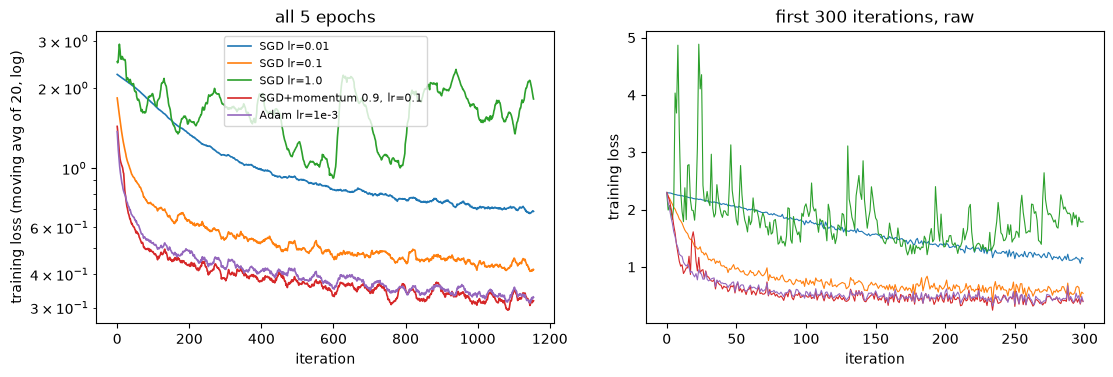

optimizer                    test accuracy after 5 epochs
SGD lr=0.01                  0.756
SGD lr=0.1                   0.830
SGD lr=1.0                   0.221
SGD+momentum 0.9, lr=0.1     0.868
Adam lr=1e-3                 0.867


In [12]:
OPTIMIZERS = ["SGD lr=0.01", "SGD lr=0.1", "SGD lr=1.0", "SGD+momentum 0.9, lr=0.1", "Adam lr=1e-3"]


def make_optimizer(name, params):
    if name == "SGD lr=0.01":
        return torch.optim.SGD(params, lr=0.01)  ### TODO_STUDENT ### plain SGD, lr = 0.01
    if name == "SGD lr=0.1":
        return torch.optim.SGD(params, lr=0.1)  ### TODO_STUDENT ### plain SGD, lr = 0.1
    if name == "SGD lr=1.0":
        return torch.optim.SGD(params, lr=1.0)  ### TODO_STUDENT ### plain SGD, lr = 1.0
    if name == "SGD+momentum 0.9, lr=0.1":
        return torch.optim.SGD(params, lr=0.1, momentum=0.9)  ### TODO_STUDENT ### SGD with momentum 0.9, lr = 0.1
    if name == "Adam lr=1e-3":
        return torch.optim.Adam(params, lr=1e-3)  ### TODO_STUDENT ### Adam, lr = 1e-3
    raise ValueError(name)


opt_hist = {}
for name in OPTIMIZERS:
    torch.manual_seed(SEED)
    net = mlp()
    opt_hist[name] = train_and_log(net, make_optimizer(name, net.parameters()), Xt_fm_tr, yt_fm_tr,
                                   Xt_fm_te, yt_fm_te, epochs=5, desc=name)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name in OPTIMIZERS:
    L = np.array(opt_hist[name]["loss"])
    axes[0].plot(np.convolve(L, np.ones(20) / 20, mode="valid"), label=name, lw=1.2)
    axes[1].plot(L[:300], label=name, lw=0.8)
axes[0].set_yscale("log"); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("training loss (moving avg of 20, log)")
axes[0].set_title("all 5 epochs"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("training loss"); axes[1].set_title("first 300 iterations, raw")
plt.show()
print(f"{'optimizer':28s} test accuracy after 5 epochs")
for name in OPTIMIZERS:
    print(f"{name:28s} {opt_hist[name]['test_acc'][-1]:.3f}")


### (E) Regularization: weight decay and dropout  [20 points]

To make overfitting visible: a wider network (784-1024-1024-10) on a fixed **5,000-image** subset,
trained with Adam (lr = 10⁻³) for 40 epochs, long enough that training accuracy clearly exceeds test
accuracy. A separate 5,000-image **validation** set (also from the training images) is used to pick
the weight-decay strength, so the test set is never used for a choice.


In [13]:
def dropout_layer(X, p):
    """Inverted dropout, training mode: zero each entry with probability p, scale the survivors by 1/(1-p)."""
    assert 0 <= p <= 1
    if p == 1:
        return torch.zeros_like(X)
    mask = (torch.rand_like(X) > p).float()  ### TODO_STUDENT ### keep each entry independently with probability 1 - p
    return mask * X / (1.0 - p)  ### TODO_STUDENT ### zero the dropped entries and rescale the survivors


class DropoutScratch(nn.Module):
    def __init__(self, p):
        super().__init__()
        self.p = p

    def forward(self, X):
        return dropout_layer(X, self.p) if self.training else X  ### TODO_STUDENT ### dropout in training mode only; identity in evaluation mode


# CHECKPOINT: statistics vs nn.Dropout, and identity in eval mode
torch.manual_seed(SEED)
X_ones = torch.ones(2000, 500)
for p in [0.2, 0.5, 0.8]:
    mine, ref = DropoutScratch(p).train()(X_ones), nn.Dropout(p).train()(X_ones)
    zeros_mine, zeros_ref = (mine == 0).float().mean().item(), (ref == 0).float().mean().item()
    print(f"  p={p}: fraction zeroed yours {zeros_mine:.3f} / nn.Dropout {zeros_ref:.3f};  mean yours {mine.mean().item():.3f} / nn.Dropout {ref.mean().item():.3f}")
    assert abs(zeros_mine - p) < 0.01, "the fraction of zeroed entries should be about p"
    assert abs(mine.mean().item() - 1.0) < 0.02, "the mean should be preserved (did you rescale by 1/(1-p)?)"
assert torch.equal(DropoutScratch(0.5).eval()(X_ones), X_ones), "in eval mode dropout must return its input unchanged"
print("CHECKPOINT PASSED")


  p=0.2: fraction zeroed yours 0.200 / nn.Dropout 0.200;  mean yours 1.000 / nn.Dropout 1.000
  p=0.5: fraction zeroed yours 0.500 / nn.Dropout 0.500;  mean yours 0.999 / nn.Dropout 1.000
  p=0.8: fraction zeroed yours 0.801 / nn.Dropout 0.800;  mean yours 0.997 / nn.Dropout 0.999
CHECKPOINT PASSED


no regularization: 100%|█████████████████████████| 1600/1600 [00:09<00:00, 176.38batch/s, epoch=40, test_acc=0.842]

weight decay 0.0001: 100%|█████████████████████████| 1600/1600 [00:10<00:00, 153.60batch/s, epoch=40, test_acc=0.842]

weight decay 0.001: 100%|█████████████████████████| 1600/1600 [00:09<00:00, 162.49batch/s, epoch=40, test_acc=0.842]

weight decay 0.003: 100%|█████████████████████████| 1600/1600 [00:09<00:00, 160.80batch/s, epoch=40, test_acc=0.843]

dropout p=0.5: 100%|█████████████████████████| 1600/1600 [00:11<00:00, 140.24batch/s, epoch=40, test_acc=0.855]

5 runs x 40 epochs: 51 s;  best weight decay by VALIDATION accuracy: weight decay 0.0001

run                     train    val   test  gap (train-test)
no regularization       0.970  0.854  0.842             0.128
weight decay 0.0001     0.965  0.857  0.842             0.123
weight decay 0.001      0.938  0.854  0.842             0.096
weight decay 0.003      0.909  0.853  0.843             0.066
dropout p=0.5           0.935  0.867  0.855             0.080


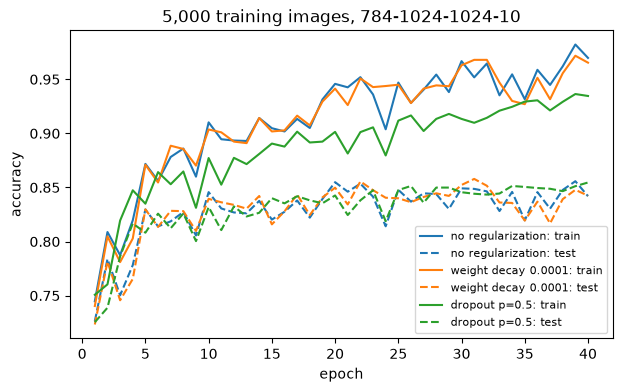

In [14]:
g = torch.Generator().manual_seed(1)
perm = torch.randperm(len(Xt_fm_tr), generator=g)
X_small, y_small = Xt_fm_tr[perm[:5000]], yt_fm_tr[perm[:5000]]
X_val, y_val = Xt_fm_tr[perm[5000:10000]], yt_fm_tr[perm[5000:10000]]


def wide_mlp(dropout=None):
    layers = [nn.Linear(784, 1024), nn.ReLU()]
    if dropout:
        layers.append(DropoutScratch(dropout))
    layers += [nn.Linear(1024, 1024), nn.ReLU()]
    if dropout:
        layers.append(DropoutScratch(dropout))
    layers.append(nn.Linear(1024, 10))
    return nn.Sequential(*layers)


def run_regularized(dropout=None, weight_decay=0.0, epochs=40):
    torch.manual_seed(SEED)
    net = wide_mlp(dropout)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=weight_decay)  ### TODO_STUDENT ### Adam, lr=1e-3, with the L2 penalty passed as weight_decay
    desc = f"dropout p={dropout}" if dropout else (f"weight decay {weight_decay:g}" if weight_decay else "no regularization")
    return train_and_log(net, opt, X_small, y_small, Xt_fm_te, yt_fm_te, epochs=epochs, batch_size=128,
                         X_val=X_val, y_val=y_val, desc=desc)


t0 = time.time()
reg_hist = {"no regularization": run_regularized()}
for wd in [1e-4, 1e-3, 3e-3]:
    reg_hist[f"weight decay {wd:g}"] = run_regularized(weight_decay=wd)
best_wd = max([k for k in reg_hist if k.startswith("weight")], key=lambda k: reg_hist[k]["val_acc"][-1])
reg_hist["dropout p=0.5"] = run_regularized(dropout=0.5)
print(f"5 runs x 40 epochs: {time.time() - t0:.0f} s;  best weight decay by VALIDATION accuracy: {best_wd}")

print(f"\n{'run':22s} {'train':>6s} {'val':>6s} {'test':>6s} {'gap (train-test)':>17s}")
for k, h in reg_hist.items():
    print(f"{k:22s} {h['train_acc'][-1]:6.3f} {h['val_acc'][-1]:6.3f} {h['test_acc'][-1]:6.3f} {h['train_acc'][-1] - h['test_acc'][-1]:17.3f}")

plt.figure(figsize=(7, 4))
for k, color in [("no regularization", "C0"), (best_wd, "C1"), ("dropout p=0.5", "C2")]:
    ep = range(1, len(reg_hist[k]["train_acc"]) + 1)
    plt.plot(ep, reg_hist[k]["train_acc"], "-", color=color, label=f"{k}: train")
    plt.plot(ep, reg_hist[k]["test_acc"], "--", color=color, label=f"{k}: test")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(fontsize=8); plt.title("5,000 training images, 784-1024-1024-10")
plt.show()


**Reading the table (E).** The table reports the final train/test gap for each run. Note what you see (which runs shrink the gap, and which improve test accuracy); Problem 5 asks you to explain it.

*How to think about it.* Read one column at a time. The gap is train minus test: which runs make it smaller? Now the test column alone: which runs actually raise it? A gap can shrink because test accuracy went *up* or because train accuracy went *down*. Which happened for each regularizer?

*Your answer here.*

- **No regularization overfits:** train accuracy keeps rising (0.970) while test stays around 0.842. A wide network with many parameters, trained on only 5,000 images, memorizes the training set (p.7).
- **Weight decay** shrinks the gap only by lowering train accuracy (the stronger the decay, the lower the train accuracy). Test accuracy stays about the same, so here it doesn't help on new images. Validation even picked the weakest decay (0.0001).
- **Dropout** is the only one that shrinks the gap *and* raises test accuracy (0.855): train goes down and test goes up.

### (F) Initialization and vanishing gradients  [15 points]

A 10-hidden-layer MLP (width 128) in four variants: {sigmoid, ReLU} × {small fixed-scale init
N(0, 0.01²), the init matched to the activation (Xavier for sigmoid, He/Kaiming for ReLU)}. First the
gradient norm of every layer's weights after one backward pass on one batch; then 2 epochs of
training each.


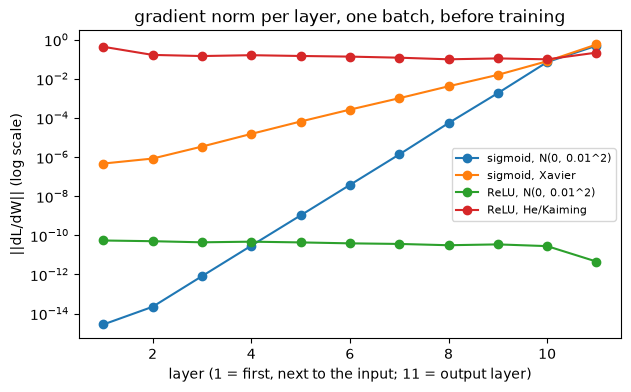

2 epochs of SGD (lr=0.1) each:


sigmoid, N(0, 0.01^2): 100%|█████████████████████████| 470/470 [00:00<00:00, 498.11batch/s, epoch=2, test_acc=0.100]

  sigmoid, N(0, 0.01^2)    test accuracy 0.100   (10 classes: chance = 0.100)


sigmoid, Xavier: 100%|█████████████████████████| 470/470 [00:00<00:00, 500.83batch/s, epoch=2, test_acc=0.100]

  sigmoid, Xavier          test accuracy 0.100   (10 classes: chance = 0.100)


ReLU, N(0, 0.01^2): 100%|█████████████████████████| 470/470 [00:00<00:00, 719.34batch/s, epoch=2, test_acc=0.100]

  ReLU, N(0, 0.01^2)       test accuracy 0.100   (10 classes: chance = 0.100)


ReLU, He/Kaiming: 100%|█████████████████████████| 470/470 [00:00<00:00, 782.40batch/s, epoch=2, test_acc=0.790]

  ReLU, He/Kaiming         test accuracy 0.790   (10 classes: chance = 0.100)


In [15]:
def deep_mlp(activation, init, depth=10, width=128):
    layers, n_in = [], 784
    for _ in range(depth):
        lin = nn.Linear(n_in, width)
        n_in = width
        if init == "small":
            nn.init.normal_(lin.weight, mean=0.0, std=0.01)  ### TODO_STUDENT ### small fixed-scale init, N(0, 0.01^2)
        elif activation == "sigmoid":
            nn.init.xavier_uniform_(lin.weight)  ### TODO_STUDENT ### Xavier/Glorot init (matched to sigmoid)
        else:
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")  ### TODO_STUDENT ### He/Kaiming init (matched to ReLU)
        nn.init.zeros_(lin.bias)
        layers += [lin, nn.Sigmoid() if activation == "sigmoid" else nn.ReLU()]
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)


def layer_grad_norms(net, X, y):
    net.zero_grad()
    loss = F.cross_entropy(net(X), y)  ### TODO_STUDENT ### one forward pass and the loss on this batch
    loss.backward()  ### TODO_STUDENT ### one backward pass
    return [m.weight.grad.norm().item() for m in net if isinstance(m, nn.Linear)]


VARIANTS = [("sigmoid", "small"), ("sigmoid", "scaled"), ("relu", "small"), ("relu", "scaled")]
LABEL = {("sigmoid", "small"): "sigmoid, N(0, 0.01^2)", ("sigmoid", "scaled"): "sigmoid, Xavier",
         ("relu", "small"): "ReLU, N(0, 0.01^2)", ("relu", "scaled"): "ReLU, He/Kaiming"}
plt.figure(figsize=(7, 4))
for v in VARIANTS:
    torch.manual_seed(SEED)
    norms = layer_grad_norms(deep_mlp(*v), Xt_fm_tr[:256], yt_fm_tr[:256])
    plt.semilogy(range(1, len(norms) + 1), norms, "o-", label=LABEL[v])
plt.xlabel("layer (1 = first, next to the input; 11 = output layer)"); plt.ylabel("||dL/dW|| (log scale)")
plt.title("gradient norm per layer, one batch, before training"); plt.legend(fontsize=8); plt.show()

print("2 epochs of SGD (lr=0.1) each:")
for v in VARIANTS:
    torch.manual_seed(SEED)
    net = deep_mlp(*v)
    h = train_and_log(net, torch.optim.SGD(net.parameters(), lr=0.1), Xt_fm_tr, yt_fm_tr, Xt_fm_te, yt_fm_te, epochs=2,
                      desc=LABEL[v])
    print(f"  {LABEL[v]:24s} test accuracy {h['test_acc'][-1]:.3f}   (10 classes: chance = 0.100)")


**Written answer (F).** Which variants learn at all? In 2–3 sentences, connect the gradient-norm plot to the chain rule you implemented in Problem 1: what happens to a product of many per-layer factors that are each smaller than 1?

*How to think about it.* In Problem 1, each sigmoid layer's backward pass multiplied the incoming gradient by σ'(net). What is the largest value σ' can ever take? Multiply ten such numbers. For ReLU, what is the derivative on the units that are active? Then think about the weights: every layer's backward pass also multiplies by W, so what does a tiny initial scale such as 0.01 do to the signal after ten layers, in the forward pass and in the backward pass? Which of your four curves stays roughly level across layers?

*Your answer here.*

Only ReLU + He/Kaiming learns (0.790); the other three stay at chance (0.100). In backpropagation, each layer multiplies the gradient by its weights and by f′(net), Δ_l = (Δ_{l+1} · W_{l+1}ᵀ) · f′(net_l) (p.6–7), so after 10 layers the gradient is a product of 10 factors, and if each one is smaller than 1 the product shrinks toward 0: the sigmoid's f′ is at most 1/4, and tiny N(0, 0.01²) weights shrink it further, so the first layers barely get updated. With ReLU and tiny weights, f′ = 1 but the weights are so small that the gradient is tiny in every layer. ReLU's f′ = 1 on active units (p.8), and He init sets the weights to the right size, so its gradient keeps its size through all layers (the only level curve in the plot).

---
## Problem 3 — Variational Autoencoder (VAE), using PyTorch  [50 points]

Problem 1's autoencoder compresses and reconstructs, but nothing organizes its codes and there's no
principled way to generate a new point. A VAE makes the latent space a probability distribution
shaped like the prior N(0, I). Data: MNIST, 784 pixel values in [0, 1]. See the VAE lecture note.

### (A) Build and train it  [20 points]

The architecture is given: a shared encoder trunk with two linear heads (μ and log σ²), and a
decoder 2 → 400 → 784 with a sigmoid output. Read it; the two-heads-on-one-trunk shape is the only
new piece. You implement what makes it a VAE: the reparameterization, the KL term, and the loss.


In [16]:
class VAE(nn.Module):
    def __init__(self, n_in=784, n_hidden=400, n_latent=2):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU())      # shared encoder trunk
        self.mu_head = nn.Linear(n_hidden, n_latent)                            # head 1: the mean mu(x)
        self.logvar_head = nn.Linear(n_hidden, n_latent)                        # head 2: log sigma^2(x)
        self.decoder = nn.Sequential(nn.Linear(n_latent, n_hidden), nn.ReLU(),  # 2 -> hidden -> 784,
                                     nn.Linear(n_hidden, n_in), nn.Sigmoid())   # pixel intensities in [0, 1]

    def encode(self, x):
        h = self.trunk(x)
        return self.mu_head(h), self.logvar_head(h)

    def reparameterize(self, mu, logvar):
        eps = torch.randn_like(mu)  ### TODO_STUDENT ### eps ~ N(0, I), same shape as mu
        return mu + torch.exp(0.5 * logvar) * eps  ### TODO_STUDENT ### z = mu + sigma * eps, with sigma = exp(logvar / 2)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def kl_to_standard_normal(mu, logvar):
    """KL( N(mu, diag(sigma^2)) || N(0, I) ): one value per row."""
    return 0.5 * torch.sum(mu ** 2 + logvar.exp() - 1 - logvar, dim=1)  ### TODO_STUDENT ### the closed-form Gaussian KL, summed over the latent dimensions


# CHECKPOINT: closed-form KL vs a Monte-Carlo estimate E_q[log q(z) - log p(z)]
torch.manual_seed(SEED)
mu_chk, logvar_chk = torch.randn(500, 2), 0.5 * torch.randn(500, 2)
q = torch.distributions.Normal(mu_chk, torch.exp(0.5 * logvar_chk))
p = torch.distributions.Normal(0.0, 1.0)
z = q.sample((20000,))
kl_mc = (q.log_prob(z) - p.log_prob(z)).sum(-1).mean(0)
kl_closed = kl_to_standard_normal(mu_chk, logvar_chk)
rel = (abs(kl_closed.sum() - kl_mc.sum()) / kl_closed.sum()).item()
print(f"total KL over 500 random (mu, logvar): closed form {kl_closed.sum().item():.1f}, Monte Carlo {kl_mc.sum().item():.1f}, relative difference {rel:.4f}")
assert kl_closed.shape == (500,), "return one KL value per row"
assert rel < 0.01, "closed-form KL and the Monte-Carlo estimate should agree to about 1%"
print("CHECKPOINT PASSED")


total KL over 500 random (mu, logvar): closed form 591.9, Monte Carlo 592.0, relative difference 0.0002
CHECKPOINT PASSED


**Written answer (A)(ii): why sampling z directly would block the gradient.**

*How to think about it.* Backprop needs, at every step between the loss and the encoder's weights, an answer to "if I nudge this input a little, how does this output change?" Ask that question about the step "draw z at random from N(μ, σ²)": if you nudge μ, what happens to one particular random draw? Is there a derivative to pass back? Now ask it about z = μ + σ·ε, where ε was drawn first and is held fixed: what is ∂z/∂μ, and ∂z/∂σ? Where did the randomness go?

*Your answer here.*

Backprop needs a derivative at every step between the loss and the encoder's weights. If z is drawn at random from N(μ, σ²), there is no formula linking z to μ and σ, so there is no ∂z/∂μ to pass back and the encoder gets no gradient (taking derivatives through a random draw is the problem). The fix is to draw the randomness first, ε ~ N(0, 1), outside the network, and then compute z = μ + σ·ε. Now z is an ordinary formula, ∂z/∂μ = 1 and ∂z/∂σ = ε, so backprop goes through z to the encoder. The randomness sits in ε, which needs no gradient.


VAE: 100%|█████████████████████████| 4690/4690 [00:11<00:00, 409.15batch/s, epoch=10, kl=5.8, recon=148.3]

VAE, 10 epochs on CPU: 11 s;  final reconstruction 148.3, KL 5.82 (nats per image)


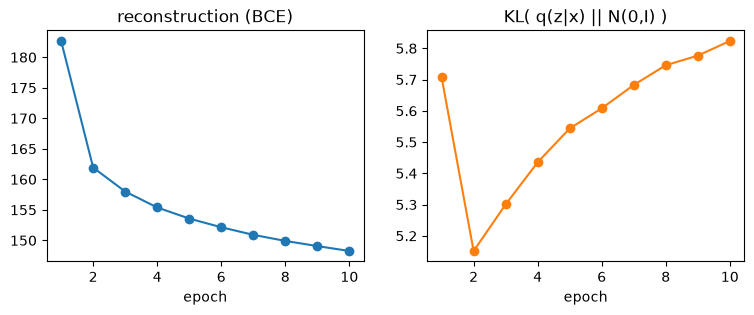

In [17]:
def vae_loss(x, x_hat, mu, logvar):
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / len(x)  ### TODO_STUDENT ### binary cross-entropy summed over pixels, averaged over the batch
    kl = kl_to_standard_normal(mu, logvar).mean()  ### TODO_STUDENT ### the KL term, averaged over the batch
    return recon, kl


def train_vae(model, X, epochs=10, batch_size=128, lr=1e-3, use_kl=True, seed=SEED, desc="VAE"):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"recon": [], "kl": []}
    bar = progress(epochs * -(-len(X) // batch_size), desc)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        tot_r = tot_k = 0.0
        for start in range(0, len(X), batch_size):
            xb = X[perm[start:start + batch_size]]
            x_hat, mu, logvar = model(xb)
            recon, kl = vae_loss(xb, x_hat, mu, logvar)
            loss = recon + kl if use_kl else recon
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot_r += recon.item() * len(xb)
            tot_k += kl.item() * len(xb)
            bar.update(1)
        hist["recon"].append(tot_r / len(X))
        hist["kl"].append(tot_k / len(X))
        bar.set_postfix(epoch=epoch + 1, recon=f"{hist['recon'][-1]:.1f}", kl=f"{hist['kl'][-1]:.1f}")
    bar.close()
    return hist


torch.manual_seed(SEED)
vae = VAE()
t0 = time.time()
vae_hist = train_vae(vae, Xt_mn_tr, epochs=10)
print(f"VAE, 10 epochs on CPU: {time.time() - t0:.0f} s;  final reconstruction {vae_hist['recon'][-1]:.1f}, KL {vae_hist['kl'][-1]:.2f} (nats per image)")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(range(1, 11), vae_hist["recon"], "o-"); axes[0].set_title("reconstruction (BCE)"); axes[0].set_xlabel("epoch")
axes[1].plot(range(1, 11), vae_hist["kl"], "o-", color="C1"); axes[1].set_title("KL( q(z|x) || N(0,I) )"); axes[1].set_xlabel("epoch")
plt.show()


### (B) Explore the latent space  [15 points]

The comparison model is given: a *plain* autoencoder with exactly your VAE's architecture, but with
the sampling and the KL term removed (its code for x is simply μ(x)).


plain AE: 100%|█████████████████████████| 4690/4690 [00:09<00:00, 477.79batch/s, epoch=10, kl=28.0, recon=146.5]

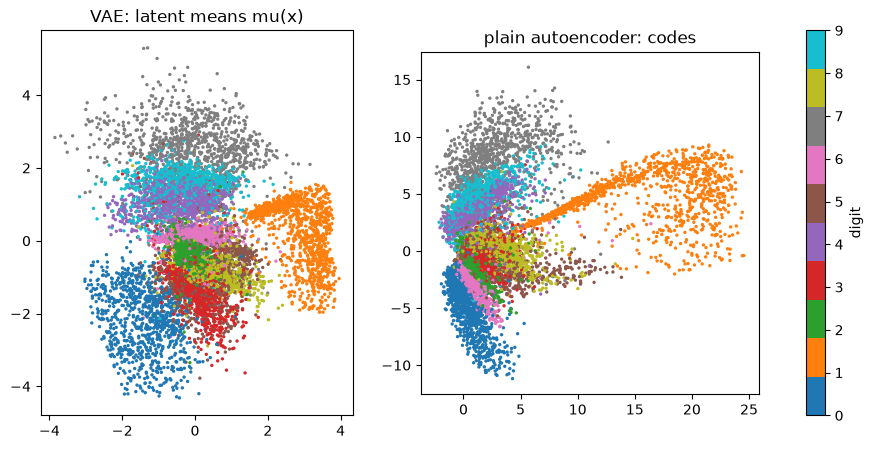

spread of the codes (std per dimension):  VAE [1.26 1.47]   plain AE [5.   4.11]


In [18]:
class PlainAE(VAE):
    """Your VAE with the sampling and the KL term removed: code(x) = mu(x), trained on reconstruction only."""

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decoder(mu), mu, logvar


torch.manual_seed(SEED)
plain_ae = PlainAE()
train_vae(plain_ae, Xt_mn_tr, epochs=10, use_kl=False, desc="plain AE")

# (i) organization: the 2-D codes of the 10,000 test digits
with torch.no_grad():
    mu_vae = vae.encode(Xt_mn_te)[0].numpy()
    mu_ae = plain_ae.encode(Xt_mn_te)[0].numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, codes, title in [(axes[0], mu_vae, "VAE: latent means mu(x)"), (axes[1], mu_ae, "plain autoencoder: codes")]:
    sc = ax.scatter(codes[:, 0], codes[:, 1], c=y_mn_te, cmap="tab10", s=2, rasterized=True)
    ax.set_title(title); ax.set_aspect("equal")
fig.colorbar(sc, ax=axes, ticks=range(10), label="digit")
plt.show()
print("spread of the codes (std per dimension):  VAE", mu_vae.std(0).round(2), "  plain AE", mu_ae.std(0).round(2))


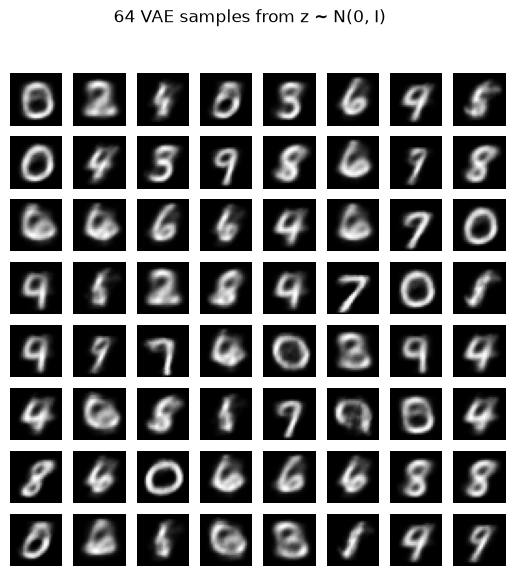

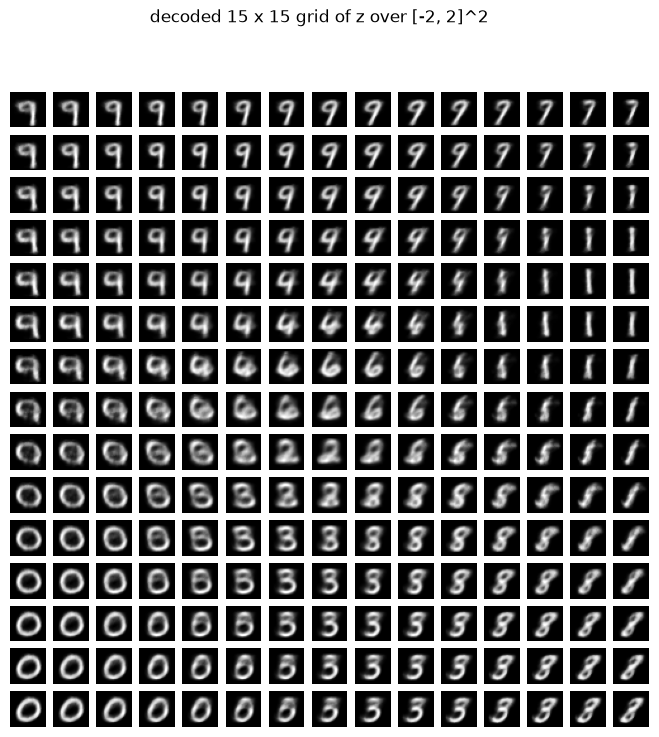

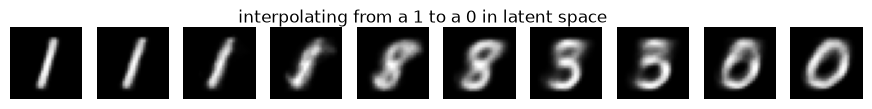

In [19]:
def show_grid(images, nrow, title, size=1.0):
    ncol = int(np.ceil(len(images) / nrow))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size))
    for ax, img in zip(np.ravel(axes), images):
        ax.imshow(img.reshape(28, 28), cmap="gray")
    for ax in np.ravel(axes):
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


vae.eval()
with torch.no_grad():
    # (ii) generation: z straight from the prior, no input image
    torch.manual_seed(SEED)
    z = torch.randn(64, 2)  ### TODO_STUDENT ### 64 draws from the prior N(0, I)
    samples = vae.decoder(z).numpy()
    # the latent "map": decode a regular 15 x 15 grid over [-2, 2]^2
    ticks = np.linspace(-2, 2, 15)
    zz = torch.tensor([[a, b] for b in ticks[::-1] for a in ticks], dtype=torch.float32)
    latent_map = vae.decoder(zz).numpy()
show_grid(samples, 8, "64 VAE samples from z ~ N(0, I)", size=0.8)
show_grid(latent_map, 15, "decoded 15 x 15 grid of z over [-2, 2]^2", size=0.55)

# (iii) interpolation between two test digits of different classes
i_a, i_b = int(np.where(y_mn_te == 1)[0][0]), int(np.where(y_mn_te == 0)[0][0])
with torch.no_grad():
    z_a, z_b = vae.encode(Xt_mn_te[[i_a]])[0], vae.encode(Xt_mn_te[[i_b]])[0]
    steps = []
    for t in np.linspace(0, 1, 10):
        z_line = (1 - t) * z_a + t * z_b  ### TODO_STUDENT ### linear interpolation between the two latent means
        steps.append(vae.decoder(z_line).numpy()[0])
show_grid(steps, 1, f"interpolating from a {y_mn_te[i_a]} to a {y_mn_te[i_b]} in latent space", size=1.1)


**Written answer (B).** Comment briefly: how do the VAE's latent codes differ from the plain autoencoder's, and what do the samples, the latent map, and the interpolation show?

*How to think about it.* Compare the two scatter plots' *axes* first: the range of the codes, and where the digits sit relative to (0, 0). Then imagine drawing z from N(0, I), a cloud of radius about 2 around the origin: in each plot, would those draws land on digit codes or in empty space? Which term of the VAE's loss pulls the codes toward that cloud? For the latent map and the interpolation, look at the regions *between* digit clusters: does the decoder still produce something digit-like there, and why would it, given how the VAE was trained?

*Your answer here.*

- **Codes:** The VAE's codes form one cloud around (0, 0) with a spread of about 1, the shape of the prior N(0, I). The plain autoencoder's codes spread much wider (std 5.0 and 4.11) and sit off to one side. The KL term in the VAE's loss pulls the codes toward N(0, I). The plain autoencoder has no such term, so nothing organizes its codes.
- **Samples:** Because the VAE's codes fill N(0, I), random draws from N(0, I) land on digit codes, so most samples look like digits. For the plain autoencoder, many such draws would land in empty space.
- **Latent map and interpolation:** Every point in the grid decodes to a digit, and digits change smoothly into their neighbours, even between clusters; the 1 → 0 path passes smoothly through 8 and 3. This works because during training the decoder sees z = μ + σ·ε, the area *around* each code, not just the code itself, so it learns to produce a digit everywhere in the cloud.


### (C) Written only  [15 points]


**Written answer (C).** Why can EM's E-step be computed exactly for a Gaussian mixture but not for this VAE's decoder, and why is a learned encoder the right fix (rather than, say, just running more EM iterations)?

*How to think about it.* An E-step computes the posterior p(z | x) ∝ p(x | z) p(z) and normalizes it. For a Gaussian mixture, z takes one of K values: how many numbers do you compute, and how do you normalize them? For the VAE, z is a continuous 2-D vector and p(x | z) is a neural network: what would normalizing require (think of a sum over K values turning into an integral over all z)? Is running more iterations a fix for a step you cannot carry out even once? Finally, count the work: 60,000 training images, each needing its own posterior, at every iteration and again for every new image, versus one network that outputs a guess for any x in one forward pass. The VAE note's remark "Why not just run EM longer?" is about exactly this.

*Your answer here.*

In a Gaussian mixture, z is one of K clusters, so the E-step p(z | x) = p(x | z) p(z) / p(x) is a simple Bayes calculation: compute K numbers and divide by their sum. In the VAE, z is a continuous 2-D vector and p(x | z) is a neural network (the decoder), so p(x) is an integral of the network's output over every possible z, which we can't compute exactly. Running more EM iterations doesn't help, because we can't do even one E-step. A learned encoder fixes this: it is trained with the KL + BCE loss to output an approximate posterior N(μ(x), σ²(x)) for *any* image in one forward pass, instead of solving a separate posterior for each of the 60,000 images at every iteration and again for every new image.


---
## Problem 4 — Generative Adversarial Network (GAN): Run It and Explain It  [10 points]

HW4 fit a Gaussian mixture to `2gaussian.txt` by maximizing a likelihood; Problem 3 maximizes a
lower bound on one; a GAN never writes down a density. **All the code in this problem is given**:
both networks (small MLPs with LeakyReLU), their optimizers (Adam with β₁ = 0.5, the usual GAN
setting), the alternating training step, and the plots. Run it, read the training step until you
can explain every line, and answer the questions from what you see. The data are standardized
(zero mean, unit variance per coordinate).


In [20]:
def standardize(A):
    return (A - A.mean(axis=0)) / A.std(axis=0)


real2 = torch.tensor(standardize(gauss2), dtype=torch.float32)
# the true component means (from HW4 Problem 3), in the same standardized coordinates
means2 = (np.array([[3.0, 3.0], [7.0, 4.0]]) - gauss2.mean(axis=0)) / gauss2.std(axis=0)
Z_DIM = 2


def make_gan(hidden=64, lr=2e-4, seed=SEED):
    torch.manual_seed(seed)
    G = nn.Sequential(nn.Linear(Z_DIM, hidden), nn.LeakyReLU(0.2), nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
                      nn.Linear(hidden, 2))                     # noise -> 2-D point (raw values, no squashing)
    D = nn.Sequential(nn.Linear(2, hidden), nn.LeakyReLU(0.2), nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
                      nn.Linear(hidden, 1))                     # 2-D point -> raw score (the loss applies the sigmoid)
    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    return G, D, opt_G, opt_D


bce = nn.BCEWithLogitsLoss()


### (A) Two modes: how a GAN trains  [5 points]

The training step below alternates one D update and one G update. Read both functions carefully:
question (A)(i) asks about the two lines marked ◀.


In [21]:
def d_step(G, D, opt_D, real):
    n = len(real)
    fake = G(torch.randn(n, Z_DIM)).detach()                                  # ◀ generated points, detached
    loss_D = bce(D(real), torch.ones(n, 1)) + bce(D(fake), torch.zeros(n, 1))  # real -> label 1, fake -> label 0
    opt_D.zero_grad()
    loss_D.backward()
    opt_D.step()
    return loss_D.item()


def g_step(G, D, opt_G, n):
    fake = G(torch.randn(n, Z_DIM))                                           # fresh points, NOT detached
    loss_G = bce(D(fake), torch.ones(n, 1))                                   # ◀ label 1: "call these real"
    opt_G.zero_grad()
    loss_G.backward()
    opt_G.step()
    return loss_G.item()


def train_gan(real, steps=4000, batch_size=256, d_steps=1, g_steps=1, checkpoints=(0, 500, 2000, 4000), desc="GAN",
              **gan_kwargs):
    G, D, opt_G, opt_D = make_gan(**gan_kwargs)
    snapshots, hist = {}, {"D": [], "G": []}
    bar = progress(steps, desc, unit="step")
    for step in range(steps + 1):
        if step in checkpoints:
            with torch.no_grad():
                snapshots[step] = G(torch.randn(3000, Z_DIM)).numpy()
        if step == steps:
            break
        for _ in range(d_steps):
            loss_D = d_step(G, D, opt_D, real[torch.randint(len(real), (batch_size,))])
        for _ in range(g_steps):
            loss_G = g_step(G, D, opt_G, batch_size)
        hist["D"].append(loss_D)
        hist["G"].append(loss_G)
        bar.update(1)
    bar.close()
    return G, snapshots, hist


def mode_fractions(samples, means):
    """Fraction of generated points closest to each true component mean."""
    d = ((samples[:, None, :] - means[None, :, :]) ** 2).sum(-1)
    return np.bincount(d.argmin(axis=1), minlength=len(means)) / len(samples)


def mode_spreads(samples, means):
    """Per-mode standard deviation (x, y) of the points closest to each mean -- checks each mode's SHAPE,
    not just its share: a mode collapsed onto a thin line has the right count but a tiny spread."""
    lab = ((samples[:, None, :] - means[None, :, :]) ** 2).sum(-1).argmin(axis=1)
    return [samples[lab == k].std(axis=0) if (lab == k).sum() > 1 else np.zeros(2) for k in range(len(means))]


t0 = time.time()
G2, snaps2, gan_hist = train_gan(real2)
print(f"GAN, 4000 steps: {time.time() - t0:.1f} s")


GAN: 100%|█████████████████████████| 4000/4000 [00:02<00:00, 1384.77step/s]

GAN, 4000 steps: 2.9 s


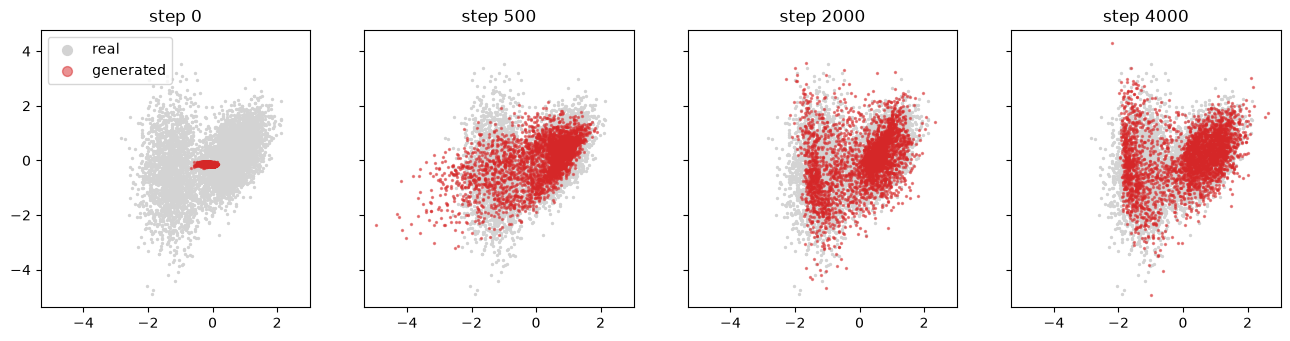

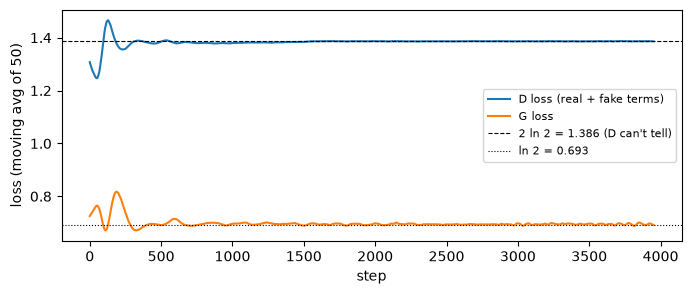

fraction of generated points nearest each true mode: [0.341 0.659]  (data: 2000 / 4000 points -> 0.333 / 0.667)
mode 0: spread (std x, y) generated [0.5  1.23]  vs real [0.53 1.14]
mode 1: spread (std x, y) generated [0.53 0.73]  vs real [0.48 0.73]


In [22]:
fig, axes = plt.subplots(1, len(snaps2), figsize=(4 * len(snaps2), 3.6), sharex=True, sharey=True)
for ax, (step, s) in zip(axes, snaps2.items()):
    ax.scatter(real2[:, 0], real2[:, 1], s=2, c="lightgray", label="real")
    ax.scatter(s[:, 0], s[:, 1], s=2, c="C3", alpha=0.5, label="generated")
    ax.set_title(f"step {step}")
axes[0].legend(markerscale=5)
plt.show()

plt.figure(figsize=(8, 3))
w = 50
plt.plot(np.convolve(gan_hist["D"], np.ones(w) / w, mode="valid"), label="D loss (real + fake terms)")
plt.plot(np.convolve(gan_hist["G"], np.ones(w) / w, mode="valid"), label="G loss")
plt.axhline(2 * np.log(2), ls="--", c="k", lw=0.8, label="2 ln 2 = 1.386 (D can't tell)")
plt.axhline(np.log(2), ls=":", c="k", lw=0.8, label="ln 2 = 0.693")
plt.xlabel("step"); plt.ylabel(f"loss (moving avg of {w})"); plt.legend(fontsize=8); plt.show()

print("fraction of generated points nearest each true mode:", mode_fractions(snaps2[4000], means2).round(3),
      " (data: 2000 / 4000 points -> 0.333 / 0.667)")
real2_np = real2.numpy()
for k, (sg, sr) in enumerate(zip(mode_spreads(snaps2[4000], means2), mode_spreads(real2_np, means2))):
    print(f"mode {k}: spread (std x, y) generated {sg.round(2)}  vs real {sr.round(2)}")


**Written answer (A).** (i) Why is `fake` detached in `d_step` but not in `g_step`, and why does `g_step` use label 1? (ii) Where does D's loss settle, and why is that the value when D can't tell real from fake? (iii) What does "implicit density" mean here, and why can you still sample from G?

*How to think about it.* (i) Ask what each step is *supposed* to change. In the D step, whose weights should move? If gradients from D's loss did flow into G, which way would they push G: toward fooling D, or toward being caught? For the label, compare the two G losses early in training, when D easily spots fakes (D(G(z)) ≈ 0.01): what is the slope of log(1 − D) there, and what is the slope of −log D? Which one gives G a useful push when G is doing badly? (ii) If D outputs 1/2 for every point, what is −log(1/2)? D's loss is the sum of two such terms, one for real and one for fake points. Compare with the dashed lines on your plot. (iii) To *draw* a sample from G, what do you need to do? To *evaluate* p(x) at some given point x, what would you need to know about G: which z's map to x, and how G stretches or squeezes space there?

*Your answer here.*

**(i)** In the D-step only D should change; G is fixed (p.17). `detach()` cuts G out of D's loss, so D's gradients can't flow into G and push it the wrong way (toward being caught). In the G-step, G must change, so the gradient has to flow from D's output back into G: no detach. Label 1 trains G to make D call its fakes real, i.e. it minimizes −log D(G(z)) instead of log(1 − D(G(z))). Early on, D easily spots fakes (D(G(z)) ≈ 0.01). There, log(1 − D) is almost flat and gives G a tiny gradient (saturated), while −log D gives a strong one (p.18).

**(ii)** D's loss settles at 2 ln 2 = 1.386 (G's at ln 2 = 0.693). When G's points look like the real data, the best D can do is output 1/2 for every point, D* = p_data / (p_data + p_G) = 1/2 (p.18), which is a random guess (p.17). Each of D's two terms is then −log(1/2) = ln 2, so the sum is 2 ln 2.

**(iii)** "Implicit density" means G gives a distribution only through its samples: there is no formula for p(x). To sample, draw z ~ N(0, I) and run G(z), one forward pass. To evaluate p(x) at a given x, we would need to know which z's map to x and how much G stretches or squeezes space there, and the network doesn't tell us that.

### (B) Three modes: when a GAN fails  [5 points]

The same GAN on `3gaussian.txt` (components of 2000, 3000, 5000 points), under three schedules: the
default (1 D step per G step), G 5× stronger, and D 5× stronger. For each run the cell prints the
fraction of samples nearest each true mode and each mode's spread, next to the real data's. A mode
can have the right *share* of points but the wrong *shape*: check both.


default:   0%|                         | 0/4000 [00:00<?, ?step/s]

default (1 D step : 1 G step)      fractions nearest each mode [0.205 0.301 0.494]  (data 0.2 / 0.3 / 0.5)   3 s
                                   per-mode spread (std x, y): (0.54, 0.68)  (0.41, 0.42)  (0.52, 0.40)


G overpowers D: 100%|█████████████████████████| 4000/4000 [00:08<00:00, 493.35step/s]

G overpowers D (1 D : 5 G steps)   fractions nearest each mode [0.    0.994 0.006]  (data 0.2 / 0.3 / 0.5)   8 s
                                   per-mode spread (std x, y): (0.00, 0.00)  (0.26, 0.69)  (0.05, 0.07)


D stronger: 100%|█████████████████████████| 4000/4000 [00:09<00:00, 440.22step/s]

D stronger (5 D : 1 G steps)       fractions nearest each mode [0.21  0.301 0.489]  (data 0.2 / 0.3 / 0.5)   9 s
                                   per-mode spread (std x, y): (0.57, 0.80)  (0.50, 0.48)  (0.55, 0.46)


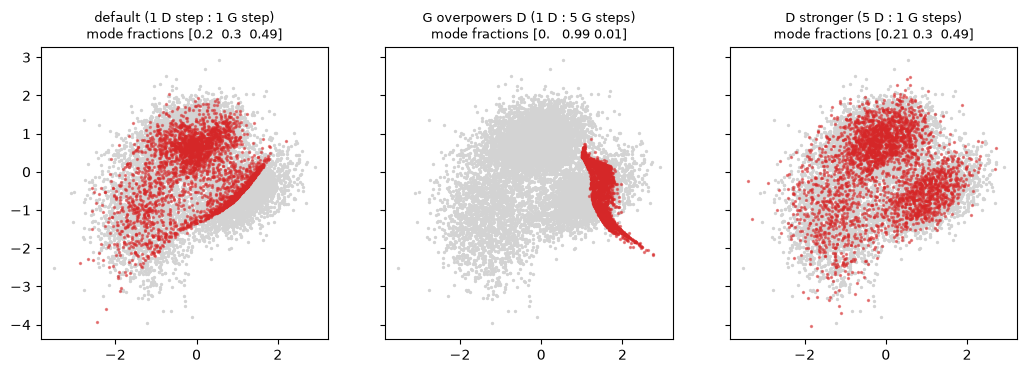

real data                          per-mode spread (std x, y): (0.58, 0.77)  (0.54, 0.48)  (0.56, 0.45)


In [23]:
real3 = torch.tensor(standardize(gauss3), dtype=torch.float32)
means3 = (np.array([[3.0, 3.0], [7.0, 4.0], [5.0, 7.0]]) - gauss3.mean(axis=0)) / gauss3.std(axis=0)

settings = {"default (1 D step : 1 G step)": dict(),
            "G overpowers D (1 D : 5 G steps)": dict(g_steps=5),
            "D stronger (5 D : 1 G steps)": dict(d_steps=5)}
fig, axes = plt.subplots(1, len(settings), figsize=(4.2 * len(settings), 3.8), sharex=True, sharey=True)
for ax, (name, kw) in zip(axes, settings.items()):
    t0 = time.time()
    _, snaps, _ = train_gan(real3, checkpoints=(4000,), desc=name.split(" (")[0], **kw)
    frac = mode_fractions(snaps[4000], means3)
    ax.scatter(real3[:, 0], real3[:, 1], s=2, c="lightgray")
    ax.scatter(snaps[4000][:, 0], snaps[4000][:, 1], s=2, c="C3", alpha=0.5)
    ax.set_title(f"{name}\nmode fractions {frac.round(2)}", fontsize=9)
    print(f"{name:34s} fractions nearest each mode {frac.round(3)}  (data 0.2 / 0.3 / 0.5)   {time.time() - t0:.0f} s")
    print(f"{'':34s} per-mode spread (std x, y): " + "  ".join(f"({a:.2f}, {b:.2f})" for a, b in mode_spreads(snaps[4000], means3)))
plt.show()
print(f"{'real data':34s} per-mode spread (std x, y): " + "  ".join(f"({a:.2f}, {b:.2f})" for a, b in mode_spreads(real3.numpy(), means3)))


**Written answer (B).** What happens under each schedule (use the printed shares *and* spreads)? Explain mode collapse in terms of what G is rewarded for. Why is HW4's EM far less prone to this failure?

*How to think about it.* Use the printout. The shares tell you how much of G's output lands near each mode (compare with 0.2 / 0.3 / 0.5); the spreads tell you how *wide* each generated mode is (compare with the real data's row). A run can have the right shares and still squeeze a mode too narrow. For the mechanism, look at G's loss: it asks only "does the *current* D think my points are real?" Is there any term that penalizes G for leaving a mode empty? What happens if G gets 5 moves before D can react, and what changes when D gets 5 moves first? For EM, every real point contributes log p(x) to its objective: what happens to that sum if a whole cluster has no component near it? (See the GAN note's "Common Failure Modes", especially "Who moves faster".)

*Your answer here.*

With the default setting (1 D step for 1 G step), the generated points are split across the 3 modes in the right amounts (0.205 / 0.301 / 0.494). But one mode is squeezed into a thin curved line, so it is narrower than the real data. The count is right but the shape is wrong.
When G gets 5 steps for every D step, almost all the points (99%) end up on one mode and the other two are nearly empty. This is mode collapse. When D gets 5 steps for every G step, both the amounts and the spreads match the real data, so this is the best run.
Mode collapse happens because G is only rewarded for fooling the current D. Nothing in G's loss punishes it for leaving a mode empty. So when G gets many steps before D can react, it moves all its points to the one spot D currently thinks is most real. When D is stronger, it quickly learns that the crowded spot is fake, so G has to spread its points out.
EM does not have this problem because it maximizes log p(x) for every real point. If a cluster had no component near it, those points would get a very low p(x) and the total would drop a lot. So EM is forced to cover every cluster. A GAN never checks the real points against G, so it gets no such penalty.

---
## Problem 5 (THEORY) — Why Dropout Lowers Train Accuracy but Raises Test Accuracy  [25 points]

In Problem 2(E), adding dropout most likely *lowered* your training accuracy, raised (or held) your
test accuracy, and shrank the train/test gap. (If your run didn't show this clearly, say so and
explain why your setup might not show it.) In a short written answer, explain why dropout produces
this pattern. Then explain (conceptually) why dropout is turned *off* at test time rather than left
on, and what the 1/(1−p) scaling in your inverted-dropout implementation is for.


**Answer.**

*How to think about it.* During training, a network with dropout can never count on any particular hidden unit being present. What does that force each unit to learn, compared with a network whose units can rely on a few partners always being there? Why would that hurt on the training set but help on new data? For test time: would you rather predict with one random thinned network, or with the full network? And if each unit was present only a fraction (1 − p) of the time during training, what happens to the size of the next layer's input when all units are suddenly present, unless something is rescaled?

*Your answer here.*

With dropout, some hidden units are randomly turned off at every training step, so the network cannot depend on any particular unit always being there. Each unit has to learn something useful on its own, and the network cannot memorize the training images through specific combinations of units. So it fits the training data less closely (train accuracy drops from 0.970 to 0.935), but it does better on new images (test accuracy goes up from 0.842 to 0.855), and the gap gets smaller. A wide network with many parameters overfits easily on only 5,000 images (p.7), and dropout reduces that.
At test time we want the best and the same prediction every time. A randomly thinned network would give noisier and weaker predictions. Hence dropout is turned off, and the full network works like an average of all the thinned networks it saw during training.
During training each unit is only present (1 − p) of the time, so on average the next layer gets a smaller input than it would with all units on. Scaling the kept units by 1/(1 − p) keeps the average input the same (the checkpoint shows the mean stays at about 1.000). So when all units are on at test time, the next layer gets inputs of the same size as during training, and nothing needs to be rescaled.

---
## Problem 6 (THEORY) — Diagnosing the Learning Rate from a Loss Curve  [25 points]

Two students train the same network with gradient descent and plot training loss vs. iteration.
Student A's curve decreases for a few iterations, then starts oscillating wildly and trending upward.
Student B's curve decreases smoothly but extremely slowly, flattening out after many iterations at a
loss still far above what a properly-tuned run achieves. In a short written answer, diagnose each
student's problem in terms of the learning rate and explain the *mechanism* behind each pattern (not
just "it's too big/small"; think of the step size relative to the curvature of the loss). Point to
which of your own Problem 2(D) curves, if any, look like A's or B's.

A third student, C, trains with minibatch SGD. C's curve drops quickly, then settles into a band that
keeps jittering up and down, and it gets no narrower or lower even when C trains ten times longer.
Nothing diverges, and C's loss evaluated once per epoch on the *whole* training set is smooth. Where
does the jitter come from? (It is not the curvature story above.) Name two changes that would let C's
loss settle lower, and what each one costs. Which of your raw Problem 2(D) curves show a band like this?


**Answer.**

*How to think about it.* Use the 1-D picture from the NN_BASICS note (§13.1): one gradient step multiplies the distance to the minimum by (1 − ηλ), where λ is the curvature. What happens to that factor, and to the distance, when ηλ > 2? When ηλ is tiny? For Student C: a minibatch gradient is an *estimate* built from a few hundred examples. Near the minimum, where the true gradient is almost zero, what is left in the estimate? With a fixed step size, can that leftover ever die out, and what would you have to change for it to?

*Your answer here.*

**Student A: learning rate too big.** Near a minimum, one gradient step multiplies the distance to the minimum by (1 − ηλ), where λ is how sharply the loss curves (its curvature). If ηλ > 2, this factor is bigger than 1 in size, so each step jumps over the minimum and lands farther away on the other side: the loss oscillates and grows. It decreases at first because the steps start out small relative to the curvature; once the loss reaches a steeper region, the steps overshoot. My SGD lr = 1.0 curve looks like this: it jumps wildly, dips, then climbs back up, and ends at 0.221 test accuracy.

**Student B: learning rate too small.** If ηλ is tiny, (1 − ηλ) is almost 1, so each step removes only a tiny part of the distance to the minimum. The loss falls smoothly but very slowly and looks flat long before it reaches a good value. My SGD lr = 0.01 curve looks like this: smooth but slow, and still well above the others after 5 epochs (test 0.756 vs 0.868 for momentum).

**Student C: minibatch noise.** Each minibatch gradient is only an estimate from a few hundred examples. Near the minimum the true gradient is almost zero, but the estimate still has noise. With a fixed step size, every step moves the weights by η × that noise, so the loss keeps bouncing in a band that never shrinks. The whole-training-set loss is smooth because it averages over all examples. Two fixes:
1. **Lower the learning rate over time (decay):** smaller steps make the band shrink. Cost: slower progress, and one more setting to tune.
2. **Bigger minibatches:** a less noisy gradient estimate. Cost: more computation and memory per step, and fewer updates per epoch.

My raw lr = 0.1, momentum and Adam curves show this band after about 50 iterations.

---
## OPTIONAL PROBLEMS [no credit]


## Problem 8 — Backprop Equations in Matrix Form  [optional, no credit]

For Problem 2's network on a minibatch X (n rows): Z₁ = XW₁ + b₁, H = ReLU(Z₁), O = HW₂ + b₂,
P = softmax(O), and G = (P − Y)/n with Y the one-hot labels. Then

* dW₂ = Hᵀ G,  db₂ = 1ᵀ G (column sums of G)
* dH = G W₂ᵀ,  dZ₁ = dH ⊙ 1[Z₁ > 0]
* dW₁ = Xᵀ dZ₁,  db₁ = 1ᵀ dZ₁

The cell below evaluates these four expressions directly and checks them against your layer
classes.


In [25]:
'''
rng = np.random.default_rng(SEED)
net9 = Network([Linear(13, 8, rng), ReLU(), Linear(8, 3, rng)], SoftmaxCrossEntropy())
Xb, yb = X_wine_tr[:32], y_wine_tr[:32]
net9.loss.forward(net9.forward(Xb), yb)
net9.backward()
L1, L2 = net9.linear_layers()
n = len(Xb)
Z1 = Xb @ L1.W + L1.b
Hh = np.maximum(Z1, 0)
P = net9.loss.p
Y = np.eye(3)[yb]
Gm = ...  ### TODO_STUDENT ### (optional) dL/dO in matrix form
dW2 = ...  ### TODO_STUDENT ### (optional) dL/dW2
db2 = ...  ### TODO_STUDENT ### (optional) dL/db2
dZ1 = ...  ### TODO_STUDENT ### (optional) dL/dZ1 = (G W2^T) masked by ReLU'
dW1 = ...  ### TODO_STUDENT ### (optional) dL/dW1
db1 = ...  ### TODO_STUDENT ### (optional) dL/db1
for name, mine, layer_grad in [("dW2", dW2, L2.dW), ("db2", db2, L2.db), ("dW1", dW1, L1.dW), ("db1", db1, L1.db)]:
    assert np.allclose(mine, layer_grad), name
    print(f"{name}: matrix form matches the layer classes (max abs diff {np.abs(mine - layer_grad).max():.1e})")
'''


'\nrng = np.random.default_rng(SEED)\nnet9 = Network([Linear(13, 8, rng), ReLU(), Linear(8, 3, rng)], SoftmaxCrossEntropy())\nXb, yb = X_wine_tr[:32], y_wine_tr[:32]\nnet9.loss.forward(net9.forward(Xb), yb)\nnet9.backward()\nL1, L2 = net9.linear_layers()\nn = len(Xb)\nZ1 = Xb @ L1.W + L1.b\nHh = np.maximum(Z1, 0)\nP = net9.loss.p\nY = np.eye(3)[yb]\nGm = ...  ### TODO_STUDENT ### (optional) dL/dO in matrix form\ndW2 = ...  ### TODO_STUDENT ### (optional) dL/dW2\ndb2 = ...  ### TODO_STUDENT ### (optional) dL/db2\ndZ1 = ...  ### TODO_STUDENT ### (optional) dL/dZ1 = (G W2^T) masked by ReLU\'\ndW1 = ...  ### TODO_STUDENT ### (optional) dL/dW1\ndb1 = ...  ### TODO_STUDENT ### (optional) dL/db1\nfor name, mine, layer_grad in [("dW2", dW2, L2.dW), ("db2", db2, L2.db), ("dW1", dW1, L1.dW), ("db1", db1, L1.db)]:\n    assert np.allclose(mine, layer_grad), name\n    print(f"{name}: matrix form matches the layer classes (max abs diff {np.abs(mine - layer_grad).max():.1e})")\n'